# Lightweight Feature-Fusion Hybrid for Solar Panel Fault Classification

| Hybrid | Branch A | Branch B |
|---|---|---|
| **H2** | MobileNetV3-Small | SqueezeNet 1.1 |

**Protocol (identical to the single-model notebook, so results are directly comparable):**
deduplicated dataset (MD5 + dHash) -> stratified **80 % train / 20 % test** split (seed 42, **no validation set**) -> same preprocessing and augmentation -> same loss, optimiser, learning rates, warm-up + cosine schedule and **30 fixed epochs** -> final-epoch model evaluated once on the test set.

**Hybrid design (feature-level fusion):** both pretrained branches see the same image. Each branch output is global-average-pooled, the two vectors are **concatenated**, and a new fusion head (`Dropout -> Linear(d,128) -> ReLU -> Dropout -> Linear(128,6)`) classifies. Both backbones are fine-tuned end-to-end (backbone LR 1e-4, fusion head LR 5e-4).

**No test-set tuning:** the epoch count is fixed, there is no early stopping and no best-checkpoint selection.

## Methodology steps
1. Setup, seeds, hyperparameters
2. Dataset discovery, unreadable-file check, exact and near-duplicate removal, class distribution
3. Stratified 80/20 split
4. Preprocessing and augmentation
5. DataLoaders (a fresh, identically seeded train loader for the hybrid)
6. Hybrid architectures
7. Loss, optimiser, scheduler and training of the remaining hybrid
8. Evaluation: train and test metrics, classification reports, confusion matrices (counts and normalised)
9. Efficiency: parameters, checkpoint size, latency on the **same device** (GPU and CPU) for hybrids and their building blocks
10. Comparison against the single-model baselines
11. Save results

## 1. Setup and hyperparameters

In [1]:
import os, random, json, time, math, hashlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import MobileNet_V3_Small_Weights, SqueezeNet1_1_Weights

try:
    import timm
except ImportError as e:
    raise ImportError('timm is required for EfficientNet-Lite0. Run:  pip install timm') from e

from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_recall_fscore_support,
                             roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

# Output locations are defined before any figures/tables are generated
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
FIG_DIR = os.path.join(OUT_DIR, 'research_figures')
os.makedirs(FIG_DIR, exist_ok=True)

# ---------------- Reproducibility ----------------
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed); random.seed(worker_seed)

# ---------------- Hyperparameters (same as the single-model notebook) ----------------
IMAGE_SIZE      = 224
BATCH_SIZE      = 32          # lower to 16 if you run out of GPU memory
NUM_WORKERS     = 2
TEST_SIZE       = 0.20        # 80 / 20 split
EPOCHS          = 30          # fixed, no early stopping (no validation set)
WARMUP_EPOCHS   = 3
LR_BACKBONE     = 1e-4        # pretrained backbones
LR_HEAD         = 5e-4        # new fusion head
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.10
GRAD_CLIP_NORM  = 1.0
DROPOUT         = 0.30
LATENCY_RUNS    = 100

# ---------------- Duplicate filtering ----------------
REMOVE_EXACT_DUPES = True     # byte-identical files (MD5)
REMOVE_NEAR_DUPES  = True     # resized / re-saved copies (64-bit dHash)
DHASH_MAX_DIST     = 2        # Hamming distance <= 2 of 64 bits

HYBRID_NAMES = ['MobileNetV3S_SqueezeNet1_1']

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| AMP:', USE_AMP, '| timm', timm.__version__)
print('Hybrids queued:', HYBRID_NAMES)

Device: cuda | AMP: True | timm 1.0.30
Hybrids queued: ['MobileNetV3S_SqueezeNet1_1']


## 2. Locate the dataset, remove duplicates and inspect class distribution
Six class folders are expected (`Bird-drop`, `Clean`, `Dusty`, `Electrical-damage`, `Physical-Damage`, `Snow-Covered`).

Before splitting into train and test, this cell removes:
1. **Unreadable/corrupted files**,
2. **Exact file duplicates** (identical MD5 byte hash),
3. **Near-identical / resized duplicates** (64-bit perceptual difference hash `dHash` within `DHASH_MAX_DIST`).

Dataset root: /kaggle/input/datasets/kiyoshi732/faulty-solar-panel-images/Faulty_solar_panel
Exact duplicates removed (MD5): 254
Near/resized duplicates removed (dHash <= 2): 536
Clean unique images: 3568 / 4358 (total removed: 790)


,class,images,share_%
0,Bird-drop,545,15.3
1,Clean,723,20.3
2,Dusty,619,17.3
3,Electrical-damage,280,7.8
4,Physical-Damage,1011,28.3
5,Snow-Covered,390,10.9


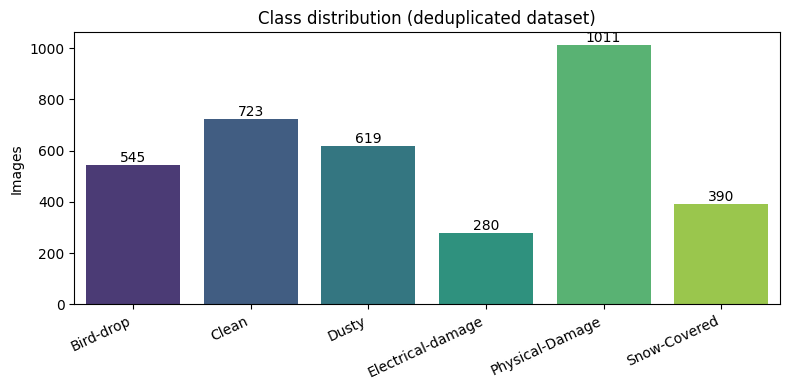

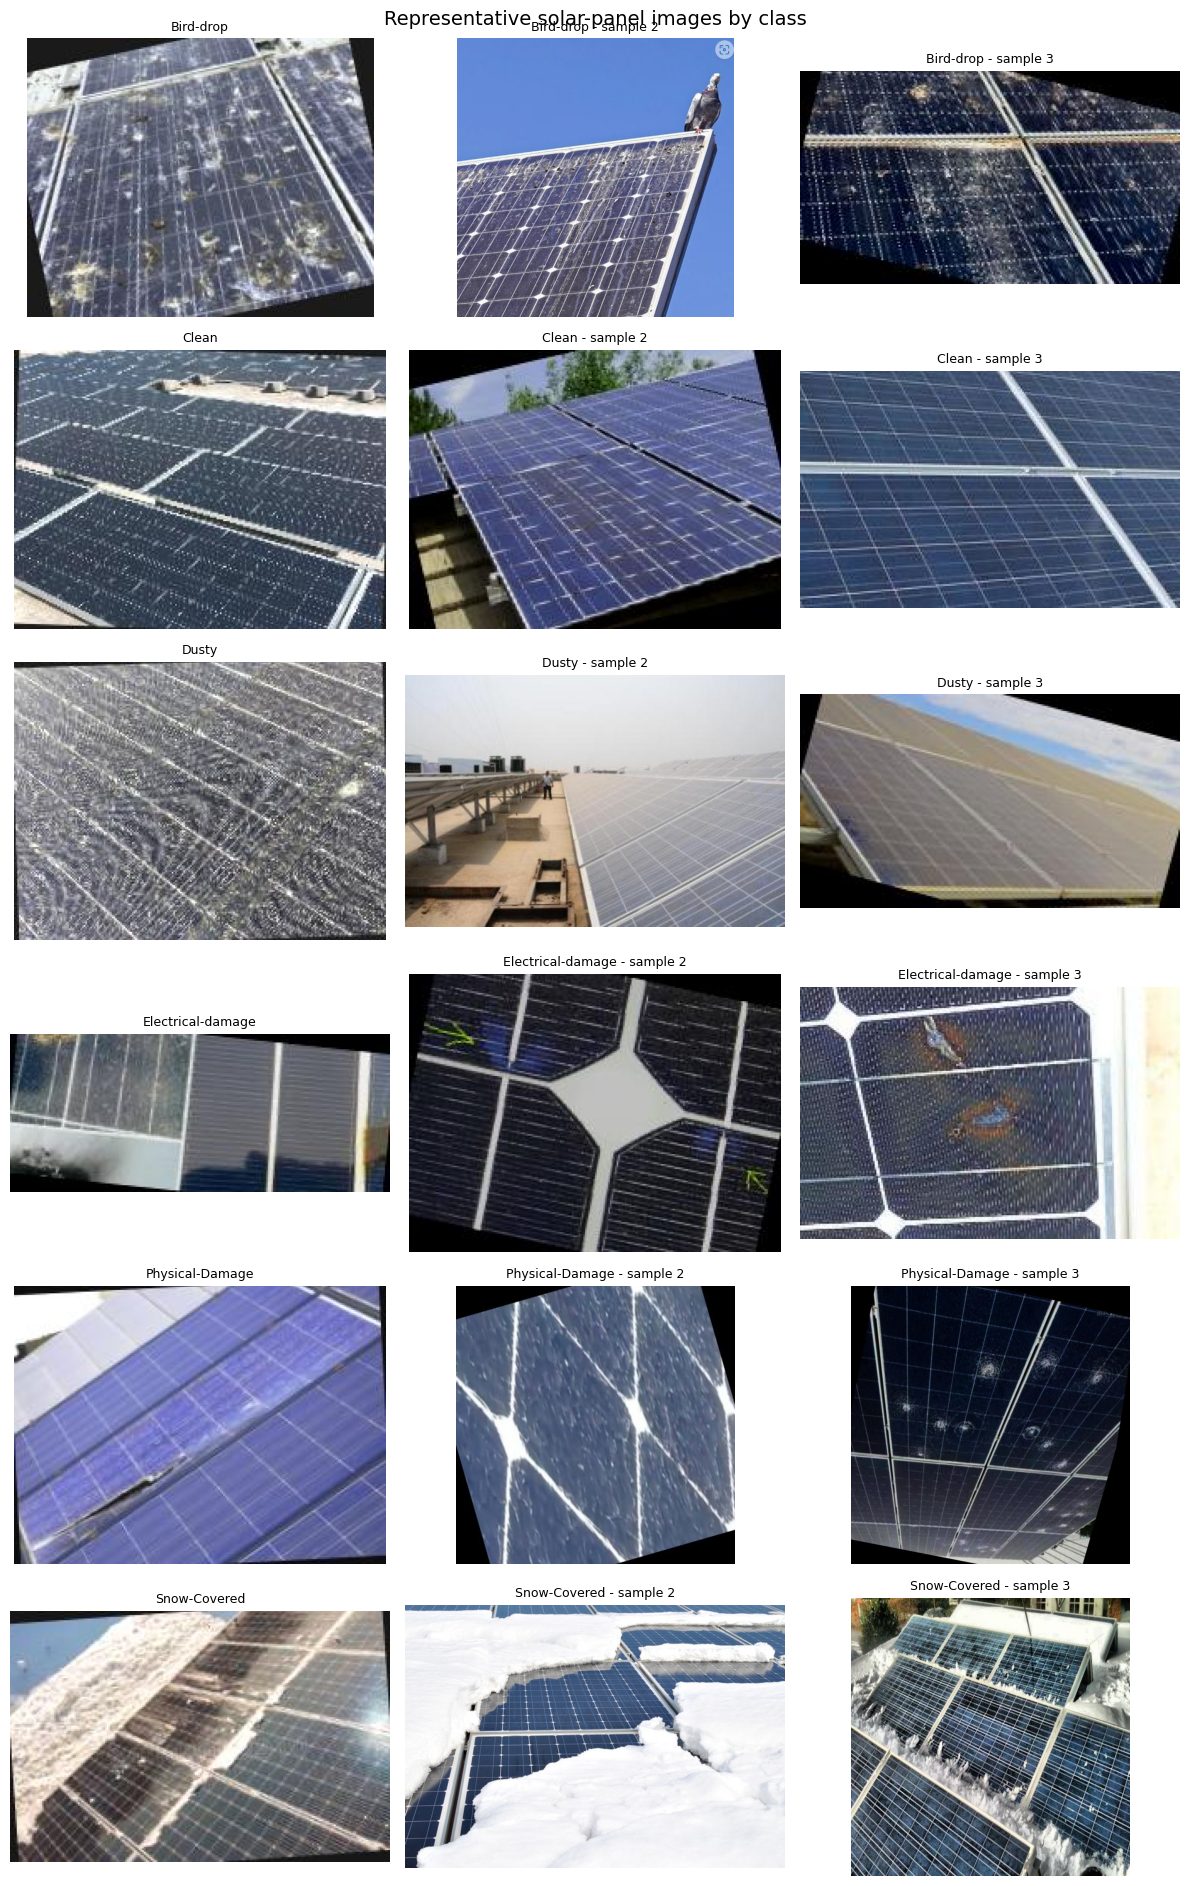

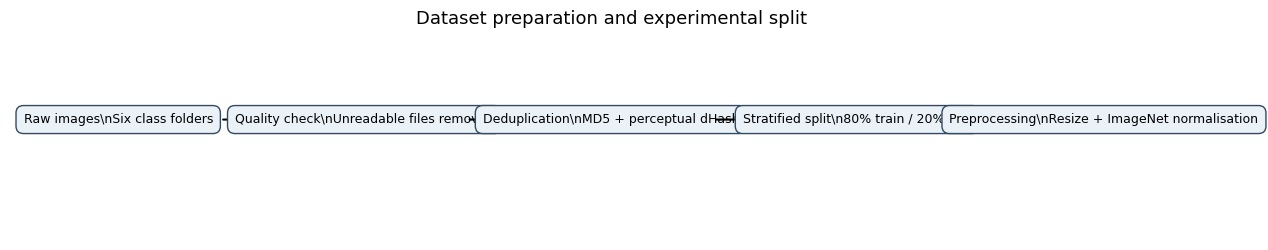

In [2]:
EXPECTED_CLASSES = ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']
VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp')

DATASET_ROOT = None   # e.g. '/kaggle/input/.../Faulty_solar_panel'  (leave None to auto-search)

def find_dataset_root(bases=('/kaggle/input', '/content', '/mnt/data', '.')):
    for base in bases:
        if not os.path.exists(base):
            continue
        for root, dirs, _ in os.walk(base):
            if set(EXPECTED_CLASSES).issubset(set(dirs)):
                return root
    raise FileNotFoundError('Dataset not found. Set DATASET_ROOT to the folder containing the six class folders.')

if DATASET_ROOT is None:
    DATASET_ROOT = find_dataset_root()
print('Dataset root:', DATASET_ROOT)

CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)

paths, labels = [], []
for idx, name in enumerate(CLASS_NAMES):
    folder = os.path.join(DATASET_ROOT, name)
    for fn in sorted(os.listdir(folder)):
        fp = os.path.join(folder, fn)
        if os.path.isfile(fp) and fn.lower().endswith(VALID_EXT):
            paths.append(fp); labels.append(idx)
paths, labels = np.array(paths), np.array(labels)
assert len(paths) > 0, 'No images found.'
raw_total = len(paths)

# 1. Check for unreadable files
bad = []
for p in paths:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad.append(p)
if bad:
    print(f'Removing {len(bad)} unreadable image(s)')
    keep = ~np.isin(paths, bad)
    paths, labels = paths[keep], labels[keep]

# 2. Remove exact file duplicates (MD5)
def md5_hash(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

exact_removed = 0
if REMOVE_EXACT_DUPES:
    seen_md5 = set()
    keep_idx = []
    for i, p in enumerate(paths):
        h = md5_hash(p)
        if h not in seen_md5:
            seen_md5.add(h)
            keep_idx.append(i)
    exact_removed = len(paths) - len(keep_idx)
    paths, labels = paths[keep_idx], labels[keep_idx]
    print(f'Exact duplicates removed (MD5): {exact_removed}')

# 3. Remove resized / re-saved duplicates (64-bit perceptual dHash)
def compute_dhash(path, hash_size=8):
    with Image.open(path) as im:
        im = im.convert('L').resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
        arr = np.asarray(im, dtype=np.int16)
    diff = arr[:, 1:] > arr[:, :-1]
    bits = diff.flatten()
    val = 0
    for b in bits:
        val = (val << 1) | int(b)
    return val

near_removed = 0
if REMOVE_NEAR_DUPES:
    seen_dhashes = []
    keep_idx = []
    for i, p in enumerate(paths):
        dh = compute_dhash(p)
        is_dup = any((dh ^ prev).bit_count() <= DHASH_MAX_DIST for prev in seen_dhashes)
        if not is_dup:
            seen_dhashes.append(dh)
            keep_idx.append(i)
    near_removed = len(paths) - len(keep_idx)
    paths, labels = paths[keep_idx], labels[keep_idx]
    print(f'Near/resized duplicates removed (dHash <= {DHASH_MAX_DIST}): {near_removed}')

print(f'Clean unique images: {len(paths)} / {raw_total} (total removed: {raw_total - len(paths)})')

counts = np.bincount(labels, minlength=NUM_CLASSES)
display(pd.DataFrame({'class': CLASS_NAMES, 'images': counts, 'share_%': (100*counts/counts.sum()).round(1)}))

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=CLASS_NAMES, y=counts, hue=CLASS_NAMES, palette='viridis', legend=False)
for i, c in enumerate(counts): ax.text(i, c, str(c), ha='center', va='bottom')
plt.title('Class distribution (deduplicated dataset)'); plt.xticks(rotation=25, ha='right'); plt.ylabel('Images')
plt.tight_layout(); plt.show()

# Research figure: representative original images from every class (classwise grid)
SAMPLES_PER_CLASS = 3
fig, axes = plt.subplots(NUM_CLASSES, SAMPLES_PER_CLASS, figsize=(4*SAMPLES_PER_CLASS, 3.2*NUM_CLASSES))
for class_idx, class_name in enumerate(CLASS_NAMES):
    class_paths = paths[labels == class_idx]
    chosen = np.random.default_rng(SEED + class_idx).choice(
        class_paths, size=min(SAMPLES_PER_CLASS, len(class_paths)), replace=False)
    for col in range(SAMPLES_PER_CLASS):
        ax = axes[class_idx, col] if NUM_CLASSES > 1 else axes[col]
        if col < len(chosen):
            with Image.open(chosen[col]) as im:
                ax.imshow(im.convert('RGB'))
            ax.set_title(class_name if col == 0 else f'{class_name} - sample {col+1}', fontsize=9)
        ax.axis('off')
plt.suptitle('Representative solar-panel images by class', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_dataset_samples_classwise.png'), dpi=300, bbox_inches='tight')
plt.show()

# Research figure: dataset preparation and split workflow
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.axis('off')
workflow = [
    ('Raw images', 'Six class folders'),
    ('Quality check', 'Unreadable files removed'),
    ('Deduplication', 'MD5 + perceptual dHash'),
    ('Stratified split', '80% train / 20% test'),
    ('Preprocessing', 'Resize + ImageNet normalisation')
]
xs = np.linspace(0.09, 0.91, len(workflow))
for i, (x, (heading, detail)) in enumerate(zip(xs, workflow)):
    ax.text(x, 0.58, heading + '\\n' + detail, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#eaf2f8', edgecolor='#34495e'))
    if i < len(workflow)-1:
        ax.annotate('', xy=(xs[i+1]-0.085, 0.58), xytext=(x+0.085, 0.58),
                    arrowprops=dict(arrowstyle='->', lw=1.5))
ax.set_title('Dataset preparation and experimental split', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_dataset_preparation_workflow.png'), dpi=300, bbox_inches='tight')
plt.show()


## 3. Stratified 80/20 train/test split
Performed **once** after deduplication, identical to the single-model notebook.

Train: 2854 (80.0%) | Test: 714 (20.0%)


,class,train,test,train_%,test_%
0,Bird-drop,436,109,15.3,15.3
1,Clean,578,145,20.3,20.3
2,Dusty,495,124,17.3,17.4
3,Electrical-damage,224,56,7.8,7.8
4,Physical-Damage,809,202,28.3,28.3
5,Snow-Covered,312,78,10.9,10.9


,class,train,test,train_%,test_%
0,Bird-drop,436,109,15.3,15.3
1,Clean,578,145,20.3,20.3
2,Dusty,495,124,17.3,17.4
3,Electrical-damage,224,56,7.8,7.8
4,Physical-Damage,809,202,28.3,28.3
5,Snow-Covered,312,78,10.9,10.9


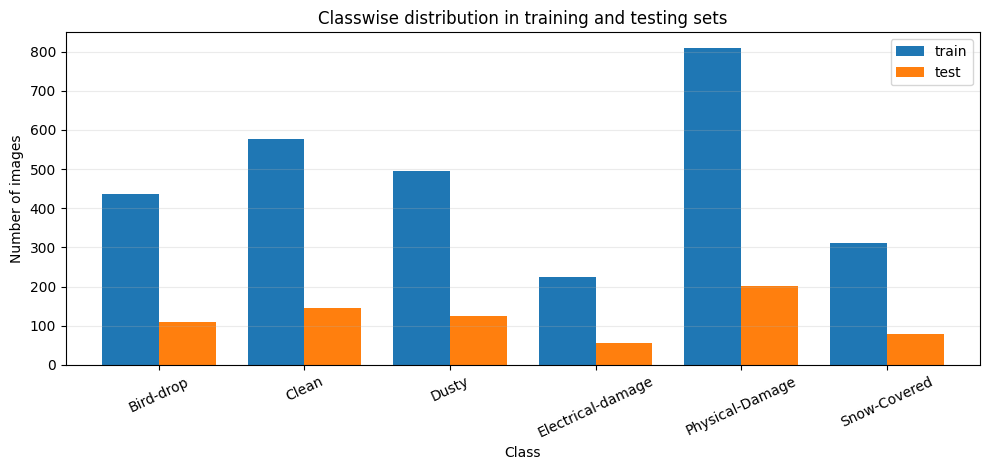

In [3]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=TEST_SIZE, random_state=SEED, stratify=labels)

assert len(set(train_paths) & set(test_paths)) == 0, 'Leakage: same image in train and test!'
assert len(train_paths) + len(test_paths) == len(paths)

print(f'Train: {len(train_paths)} ({100*len(train_paths)/len(paths):.1f}%) | '
      f'Test: {len(test_paths)} ({100*len(test_paths)/len(paths):.1f}%)')
split_df = pd.DataFrame({
    'class': CLASS_NAMES,
    'train': np.bincount(train_labels, minlength=NUM_CLASSES),
    'test':  np.bincount(test_labels,  minlength=NUM_CLASSES)})
split_df['train_%'] = (100*split_df.train/split_df.train.sum()).round(1)
split_df['test_%']  = (100*split_df.test /split_df.test.sum()).round(1)
display(split_df)

# Research table/figure: classwise image counts in the training and testing partitions
display(split_df.style.format({'train_%':'{:.1f}', 'test_%':'{:.1f}'}))
ax = split_df.set_index('class')[['train', 'test']].plot(
    kind='bar', figsize=(10, 4.8), width=0.78)
ax.set_title('Classwise distribution in training and testing sets')
ax.set_xlabel('Class'); ax.set_ylabel('Number of images')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_train_test_class_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()


## 4. Preprocessing and augmentation
- **Both sets:** resize to 224x224, convert to tensor, normalise with ImageNet mean/std.
- **Train only:** random resized crop, horizontal flip, small rotation, colour jitter, random erasing.
- **Test:** deterministic transform only, no augmentation.

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.10, scale=(0.02, 0.08), ratio=(0.3, 3.3), value='random'),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
print('Transforms ready (IMAGE_SIZE =', IMAGE_SIZE, ')')

Transforms ready (IMAGE_SIZE = 224 )


## 5. Datasets and DataLoaders
A **fresh, identically seeded** train loader is created for each hybrid, so both hybrids see exactly the same sequence of batches and neither depends on the order in which they are trained.

Batches per epoch (train): 89 | test batches: 23


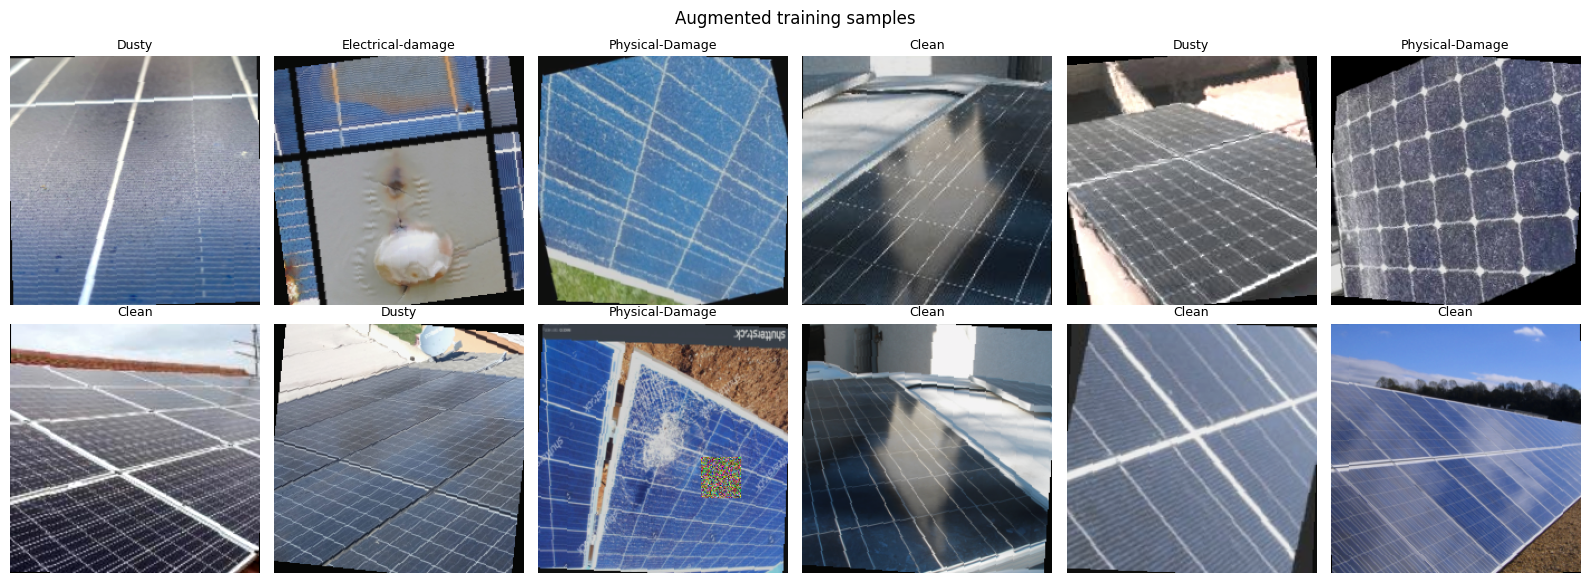

In [5]:
class SolarPanelDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            im = im.convert('RGB')
        return self.transform(im), int(self.labels[i])

train_ds      = SolarPanelDataset(train_paths, train_labels, train_transform)
train_eval_ds = SolarPanelDataset(train_paths, train_labels, eval_transform)   # un-augmented train images
test_ds       = SolarPanelDataset(test_paths,  test_labels,  eval_transform)

common = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'), worker_init_fn=seed_worker)

def make_train_loader():
    gen = torch.Generator(); gen.manual_seed(SEED)
    return DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=gen, **common)

train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH_SIZE, shuffle=False, **common)
test_loader       = DataLoader(test_ds,       batch_size=BATCH_SIZE, shuffle=False, **common)
print('Batches per epoch (train):', len(make_train_loader()), '| test batches:', len(test_loader))

inv = transforms.Normalize([-m/s for m, s in zip(MEAN, STD)], [1/s for s in STD])
imgs, lbls = next(iter(make_train_loader()))
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, im, lb in zip(axes.ravel(), imgs[:12], lbls[:12]):
    ax.imshow(inv(im).clamp(0, 1).permute(1, 2, 0)); ax.set_title(CLASS_NAMES[lb], fontsize=9); ax.axis('off')
plt.suptitle('Augmented training samples'); plt.tight_layout(); plt.show()

## 6. Hybrid architectures
Each **branch** is a pretrained feature extractor that returns one pooled vector per image:

| Branch | Source | Output dim |
|---|---|---|
| MobileNetV3-Small | torchvision, ImageNet weights, `features` + global average pool | 576 |
| SqueezeNet 1.1 | torchvision, ImageNet weights, `features` + global average pool | 512 |

`FusionHybrid` concatenates the two vectors and applies the fusion head. Hybrid inputs use the same ImageNet normalisation as the single-model runs (needed for a like-for-like comparison).

In [6]:
def make_linear_head(in_features, num_classes):
    return nn.Sequential(
        nn.Dropout(p=DROPOUT),
        nn.Linear(in_features, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(p=DROPOUT * 0.5),
        nn.Linear(128, num_classes),
    )

class MobileNetV3SmallBranch(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        m = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
        self.features = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = m.classifier[0].in_features          # 576
    def forward(self, x):
        return torch.flatten(self.pool(self.features(x)), 1)

class SqueezeNetBranch(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        m = models.squeezenet1_1(weights=SqueezeNet1_1_Weights.IMAGENET1K_V1 if pretrained else None)
        self.features = m.features                          # ends with fire9 -> 512 channels
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 512
    def forward(self, x):
        return torch.flatten(self.pool(self.features(x)), 1)

class FusionHybrid(nn.Module):
    def __init__(self, branch_a, branch_b, num_classes):
        super().__init__()
        self.branch_a, self.branch_b = branch_a, branch_b
        self.fusion_head = make_linear_head(branch_a.out_dim + branch_b.out_dim, num_classes)
    def forward(self, x):
        return self.fusion_head(torch.cat([self.branch_a(x), self.branch_b(x)], dim=1))

HYBRID_SPECS = {
    'MobileNetV3S_SqueezeNet1_1': (MobileNetV3SmallBranch, SqueezeNetBranch),
}

def build_hybrid(name, num_classes=NUM_CLASSES, pretrained=True):
    A, B = HYBRID_SPECS[name]
    net = FusionHybrid(A(pretrained), B(pretrained), num_classes)
    return net, net.fusion_head

# architecture check
for name in HYBRID_NAMES:
    set_seed()
    m, head = build_hybrid(name)
    n_a = sum(p.numel() for p in m.branch_a.parameters())
    n_b = sum(p.numel() for p in m.branch_b.parameters())
    n_h = sum(p.numel() for p in head.parameters())
    m.eval()
    with torch.no_grad():
        out = tuple(m(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE)).shape)
    print(f'{name:32s} | branch A {n_a/1e6:5.3f}M + branch B {n_b/1e6:5.3f}M + head {n_h/1e6:5.3f}M '
          f'= {(n_a+n_b+n_h)/1e6:5.3f}M | fused dim {m.branch_a.out_dim}+{m.branch_b.out_dim} | out {out}')
    del m

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 222MB/s]


Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 173MB/s]


MobileNetV3S_SqueezeNet1_1       | branch A 0.927M + branch B 0.722M + head 0.140M = 1.790M | fused dim 576+512 | out (2, 6)


### 6.1 Complete hybrid architecture diagram and layer-wise explanation

The following cells build the diagram and table directly from the implemented MobileNetV3-Small + SqueezeNet 1.1 model. The diagram is generated from the actual module graph where Graphviz is available; the table enumerates every named module and its parameter count. This is an architecture inspection only and does **not** train or alter the model.

In [7]:

# Complete architecture inspection (random initialisation is sufficient: topology is unchanged by training)
ARCH_NAME = 'MobileNetV3S_SqueezeNet1_1'
arch_model, _ = build_hybrid(ARCH_NAME, pretrained=False)
arch_model = arch_model.cpu().eval()

def explain_module(module_name, module):
    typ = type(module).__name__
    name = module_name.lower()
    if 'branch_a.features' in name:
        branch = 'MobileNetV3-Small feature extractor'
    elif 'branch_b.features' in name:
        branch = 'SqueezeNet 1.1 feature extractor'
    elif 'branch_a.pool' in name or 'branch_b.pool' in name:
        branch = 'Global average pooling to 1x1'
    elif 'fusion_head' in name:
        branch = 'Feature-fusion classifier head'
    elif 'dropout' in typ.lower():
        branch = 'Regularisation; randomly drops activations during training'
    elif isinstance(module, nn.Linear):
        branch = f'Fully connected layer: {module.in_features} to {module.out_features}'
    elif isinstance(module, nn.ReLU):
        branch = 'ReLU non-linearity'
    elif isinstance(module, nn.AdaptiveAvgPool2d):
        branch = f'Adaptive average pooling to {module.output_size}'
    elif isinstance(module, nn.Conv2d):
        branch = f'Convolution: {module.in_channels}->{module.out_channels}, kernel={module.kernel_size}, stride={module.stride}'
    elif isinstance(module, nn.BatchNorm2d):
        branch = 'Batch normalisation'
    elif isinstance(module, nn.Hardswish):
        branch = 'Hard-Swish activation'
    elif isinstance(module, nn.SiLU):
        branch = 'SiLU activation'
    elif isinstance(module, nn.MaxPool2d):
        branch = 'Max pooling'
    elif isinstance(module, nn.Sequential):
        branch = 'Sequential container for the listed child layers'
    elif module_name == '':
        branch = 'Hybrid model: parallel feature extraction followed by feature fusion'
    else:
        branch = 'Component of the corresponding backbone block'
    return branch

layer_rows = []
for layer_name, layer in arch_model.named_modules():
    params = sum(p.numel() for p in layer.parameters(recurse=False))
    trainable = sum(p.numel() for p in layer.parameters(recurse=False) if p.requires_grad)
    layer_rows.append({
        'module_path': layer_name if layer_name else 'HybridFusionModel',
        'module_type': type(layer).__name__,
        'direct_parameters': params,
        'trainable_parameters': trainable,
        'layer_explanation': explain_module(layer_name, layer)
    })
architecture_table = pd.DataFrame(layer_rows)
display(architecture_table)
architecture_table.to_csv(os.path.join(FIG_DIR, 'table_hybrid_all_layers.csv'), index=False)

# Explicit fusion dimensions and head specification for the report
fusion_summary = pd.DataFrame([
    ['Input image', 'RGB image', '3 x 224 x 224'],
    ['Branch A', 'MobileNetV3-Small features + adaptive average pool + flatten', '576'],
    ['Branch B', 'SqueezeNet 1.1 features + adaptive average pool + flatten', '512'],
    ['Feature fusion', 'Concatenation along feature dimension', '576 + 512 = 1088'],
    ['Fusion head 1', 'Dropout -> Linear(1088, 128) -> ReLU', '128'],
    ['Fusion head 2', 'Dropout -> Linear(128, 6)', '6 classes']
], columns=['stage', 'operation', 'output_shape_or_dimension'])
display(fusion_summary)
fusion_summary.to_csv(os.path.join(FIG_DIR, 'table_hybrid_architecture_summary.csv'), index=False)

# Detailed computation graph from the real model. Graphviz/torchview are optional.
try:
    import importlib.util, shutil, subprocess, sys
    if importlib.util.find_spec('torchview') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torchview', 'graphviz'])
    if shutil.which('dot') is None and os.path.exists('/usr/bin/apt-get'):
        try:
            subprocess.run(['apt-get', '-qq', 'update'], check=True, stdout=subprocess.DEVNULL)
            subprocess.run(['apt-get', '-qq', 'install', '-y', 'graphviz'], check=True, stdout=subprocess.DEVNULL)
        except Exception as install_error:
            print('System Graphviz installation skipped:', install_error)
    from torchview import draw_graph
    graph = draw_graph(arch_model, input_size=(1, 3, IMAGE_SIZE, IMAGE_SIZE),
                       expand_nested=True, roll=False, graph_name='MobileNetV3S_SqueezeNet1_1')
    graph.visual_graph.render(
        filename=os.path.join(FIG_DIR, 'fig_hybrid_all_layer_architecture'),
        format='png', cleanup=True)
    print('Saved complete expanded layer graph.')
except Exception as e:
    print('Full torchview graph could not be rendered:', repr(e))
    print('A clear branch/fusion architecture overview is generated instead.')
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.axis('off')
    boxes = [
        (0.08, 0.70, 'Input image\\n3 x 224 x 224'),
        (0.36, 0.82, 'MobileNetV3-Small\\nfeatures (all blocks)'),
        (0.36, 0.45, 'SqueezeNet 1.1\\nfeatures (Fire modules)'),
        (0.61, 0.82, 'AdaptiveAvgPool2d(1)\\nFlatten -> 576'),
        (0.61, 0.45, 'AdaptiveAvgPool2d(1)\\nFlatten -> 512'),
        (0.80, 0.63, 'Concatenate\\n1088 features'),
        (0.96, 0.63, 'Dropout -> Linear(1088,128)\\nReLU -> Dropout\\nLinear(128,6)')
    ]
    for x, y, label in boxes:
        ax.text(x, y, label, ha='center', va='center', fontsize=8,
                bbox=dict(boxstyle='round,pad=.55', facecolor='#eaf2f8', edgecolor='#34495e'))
    arrows = [((.16,.70),(.27,.82)), ((.16,.70),(.27,.45)),
              ((.46,.82),(.51,.82)), ((.46,.45),(.51,.45)),
              ((.70,.82),(.73,.66)), ((.70,.45),(.73,.60)), ((.87,.63),(.90,.63))]
    for a,b in arrows:
        ax.annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='->', lw=1.4))
    ax.set_title('MobileNetV3-Small + SqueezeNet 1.1 feature-fusion architecture')
    plt.savefig(os.path.join(FIG_DIR, 'fig_hybrid_architecture_overview.png'), dpi=300, bbox_inches='tight')
    plt.show()

del arch_model


,module_path,module_type,direct_parameters,trainable_parameters,layer_explanation
0,HybridFusionModel,FusionHybrid,0,0,Hybrid model: parallel feature extraction foll...
1,branch_a,MobileNetV3SmallBranch,0,0,Component of the corresponding backbone block
2,branch_a.features,Sequential,0,0,MobileNetV3-Small feature extractor
3,branch_a.features.0,Conv2dNormActivation,0,0,MobileNetV3-Small feature extractor
4,branch_a.features.0.0,Conv2d,432,432,MobileNetV3-Small feature extractor
...,...,...,...,...,...
270,fusion_head.0,Dropout,0,0,Feature-fusion classifier head
271,fusion_head.1,Linear,139392,139392,Feature-fusion classifier head
272,fusion_head.2,ReLU,0,0,Feature-fusion classifier head
273,fusion_head.3,Dropout,0,0,Feature-fusion classifier head


,stage,operation,output_shape_or_dimension
0,Input image,RGB image,3 x 224 x 224
1,Branch A,MobileNetV3-Small features + adaptive average ...,576
2,Branch B,SqueezeNet 1.1 features + adaptive average poo...,512
3,Feature fusion,Concatenation along feature dimension,576 + 512 = 1088
4,Fusion head 1,"Dropout -> Linear(1088, 128) -> ReLU",128
5,Fusion head 2,"Dropout -> Linear(128, 6)",6 classes


Saved complete expanded layer graph.


### 7.1 Training configuration table

In [8]:

training_config = pd.DataFrame([
    ['Input resolution', f'{IMAGE_SIZE} x {IMAGE_SIZE}'],
    ['Train/test split', '80% / 20%, stratified'],
    ['Batch size', BATCH_SIZE],
    ['Epochs', EPOCHS],
    ['Backbone learning rate', LR_BACKBONE],
    ['Fusion-head learning rate', LR_HEAD],
    ['Optimiser', 'AdamW'],
    ['Weight decay', WEIGHT_DECAY],
    ['Warm-up epochs', WARMUP_EPOCHS],
    ['Learning-rate schedule', 'Linear warm-up + cosine decay'],
    ['Loss', f'Class-weighted cross-entropy; label smoothing={LABEL_SMOOTHING}'],
    ['Gradient clipping', GRAD_CLIP_NORM],
    ['Mixed precision', USE_AMP],
    ['Random seed', SEED],
    ['Validation set', 'Not used (protocol retains fixed 80/20 train/test split)']
], columns=['parameter', 'setting'])
display(training_config)
training_config.to_csv(os.path.join(FIG_DIR, 'table_training_configuration.csv'), index=False)


,parameter,setting
0,Input resolution,224 x 224
1,Train/test split,"80% / 20%, stratified"
2,Batch size,32
3,Epochs,30
4,Backbone learning rate,0.0001
5,Fusion-head learning rate,0.0005
6,Optimiser,AdamW
7,Weight decay,0.0001
8,Warm-up epochs,3
9,Learning-rate schedule,Linear warm-up + cosine decay


## 7. Loss, optimiser, scheduler and training
- **Class-weighted cross-entropy** (weights from the training labels only) with **label smoothing**.
- **AdamW** with differential learning rates: both pretrained backbones at `LR_BACKBONE`, the new fusion head at `LR_HEAD`.
- **Schedule:** linear warm-up then cosine decay, stepped per epoch. **AMP** on GPU and **gradient clipping**.
- Fixed **30 epochs**, final-epoch model evaluated. The test set is **not** used during training.

In [9]:
class_weights = torch.tensor(
    len(train_labels) / (NUM_CLASSES * np.maximum(np.bincount(train_labels, minlength=NUM_CLASSES), 1)),
    dtype=torch.float32, device=DEVICE)
print('Class weights:', {c: round(float(w), 3) for c, w in zip(CLASS_NAMES, class_weights.cpu().numpy())})

criterion      = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)  # training
eval_criterion = nn.CrossEntropyLoss(weight=class_weights)                                   # reporting

def lr_lambda(epoch):
    if epoch < WARMUP_EPOCHS:
        return (epoch + 1) / WARMUP_EPOCHS
    progress = (epoch - WARMUP_EPOCHS) / max(1, EPOCHS - WARMUP_EPOCHS)
    return 0.5 * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def predict(m, loader, device=DEVICE):
    m.eval()
    ys, ps, probs, loss_sum, n = [], [], [], 0.0, 0
    crit = eval_criterion.to(device)
    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)
        logits = m(images)
        loss_sum += crit(logits, targets).item() * images.size(0); n += images.size(0)
        probs.append(torch.softmax(logits.float(), 1).cpu().numpy())
        ys.append(targets.cpu().numpy()); ps.append(logits.argmax(1).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(probs), loss_sum / max(n, 1)

OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
os.makedirs(OUT_DIR, exist_ok=True)

trained = {}   # name -> final-epoch model (kept on CPU for the latency benchmark later)
all_hist, all_train, all_test, all_results = {}, {}, {}, {}
LBL = np.arange(NUM_CLASSES)

for name in HYBRID_NAMES:
    print('\n' + '=' * 78); print('TRAINING HYBRID:', name); print('=' * 78)
    set_seed()
    model, head_module = build_hybrid(name)
    model = model.to(DEVICE)
    total_params = sum(p.numel() for p in model.parameters())

    head_ids = {id(p) for p in head_module.parameters()}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([
        {'params': backbone_params,               'lr': LR_BACKBONE},
        {'params': list(head_module.parameters()), 'lr': LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    train_loader = make_train_loader()

    hist = {'train_loss': [], 'train_acc': [], 'lr_head': [], 'epoch_time': []}
    t_start = time.time()
    for epoch in range(1, EPOCHS + 1):
        t_ep = time.time(); model.train()
        loss_sum, correct, n = 0.0, 0, 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer); scaler.update()
            loss_sum += loss.item() * images.size(0)
            correct  += (logits.argmax(1) == targets).sum().item()
            n        += images.size(0)
        hist['lr_head'].append(optimizer.param_groups[1]['lr'])
        scheduler.step()
        hist['train_loss'].append(loss_sum / n); hist['train_acc'].append(correct / n)
        hist['epoch_time'].append(time.time() - t_ep)
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(f'[{name}] Epoch {epoch:02d}/{EPOCHS} | loss {hist["train_loss"][-1]:.4f} | '
                  f'train acc {hist["train_acc"][-1]:.4f} | {hist["epoch_time"][-1]:.1f}s')
    train_min = (time.time() - t_start) / 60.0

    # ---- final evaluation of the final-epoch model (test set used once) ----
    y_tr, p_tr, prob_tr, loss_tr = predict(model, train_eval_loader)
    y_te, p_te, prob_te, loss_te = predict(model, test_loader)
    tr_pr, tr_rc, tr_f1, _ = precision_recall_fscore_support(y_tr, p_tr, average='macro', zero_division=0)
    te_pr, te_rc, te_f1, _ = precision_recall_fscore_support(y_te, p_te, average='macro', zero_division=0)
    _, _, per_cls_f1, _ = precision_recall_fscore_support(y_te, p_te, labels=LBL, zero_division=0)

    ckpt_path = os.path.join(OUT_DIR, f'{name}_80_20.pth')
    torch.save({'model_name': name, 'model_state_dict': model.state_dict(),
                'class_names': CLASS_NAMES, 'image_size': IMAGE_SIZE, 'epochs': EPOCHS}, ckpt_path)

    all_hist[name]  = pd.DataFrame(hist)
    all_train[name] = (y_tr, p_tr, prob_tr, confusion_matrix(y_tr, p_tr, labels=LBL))
    all_test[name]  = (y_te, p_te, prob_te, confusion_matrix(y_te, p_te, labels=LBL))
    all_results[name] = {
        'model': name,
        'params_total': int(total_params), 'params_M': round(total_params / 1e6, 4),
        'ckpt_size_MB': round(os.path.getsize(ckpt_path) / 2**20, 3),
        'train_time_min': round(train_min, 2), 'train_device': DEVICE.type,
        'train_acc': round(float(accuracy_score(y_tr, p_tr)), 4), 'train_macro_f1': round(float(tr_f1), 4),
        'test_acc': round(float(accuracy_score(y_te, p_te)), 4),
        'test_macro_precision': round(float(te_pr), 4), 'test_macro_recall': round(float(te_rc), 4),
        'test_macro_f1': round(float(te_f1), 4), 'test_loss': round(float(loss_te), 4),
        'test_misclassified': int((y_te != p_te).sum()),
        'test_f1_per_class': dict(zip(CLASS_NAMES, [round(float(x), 4) for x in per_cls_f1])),
    }
    np.savez(os.path.join(OUT_DIR, f'{name}_test_predictions.npz'), y_true=y_te, y_pred=p_te, probs=prob_te)
    print(f'[{name}] Done in {train_min:.1f} min | Train acc {all_results[name]["train_acc"]:.4f} | '
          f'Test acc {all_results[name]["test_acc"]:.4f} | Test macro-F1 {all_results[name]["test_macro_f1"]:.4f} | '
          f'errors {all_results[name]["test_misclassified"]}/{len(y_te)}')

    trained[name] = copy.deepcopy(model).cpu().eval()
    del model, optimizer, scheduler, scaler, train_loader
    if torch.cuda.is_available(): torch.cuda.empty_cache()

Class weights: {'Bird-drop': 1.091, 'Clean': 0.823, 'Dusty': 0.961, 'Electrical-damage': 2.124, 'Physical-Damage': 0.588, 'Snow-Covered': 1.525}

TRAINING HYBRID: MobileNetV3S_SqueezeNet1_1
[MobileNetV3S_SqueezeNet1_1] Epoch 01/30 | loss 1.4594 | train acc 0.4684 | 28.6s
[MobileNetV3S_SqueezeNet1_1] Epoch 05/30 | loss 0.6697 | train acc 0.9308 | 25.3s
[MobileNetV3S_SqueezeNet1_1] Epoch 10/30 | loss 0.5484 | train acc 0.9870 | 24.6s
[MobileNetV3S_SqueezeNet1_1] Epoch 15/30 | loss 0.5247 | train acc 0.9937 | 24.1s
[MobileNetV3S_SqueezeNet1_1] Epoch 20/30 | loss 0.5117 | train acc 0.9972 | 24.3s
[MobileNetV3S_SqueezeNet1_1] Epoch 25/30 | loss 0.5056 | train acc 0.9989 | 24.6s
[MobileNetV3S_SqueezeNet1_1] Epoch 30/30 | loss 0.5052 | train acc 0.9986 | 23.4s
[MobileNetV3S_SqueezeNet1_1] Done in 12.2 min | Train acc 0.9947 | Test acc 0.9664 | Test macro-F1 0.9689 | errors 24/714


## 8. Training curves

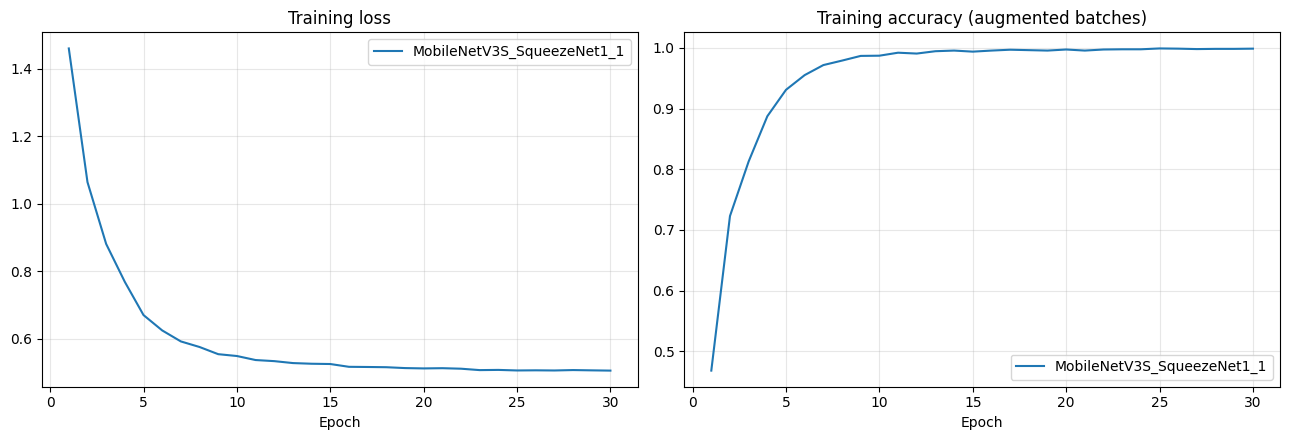

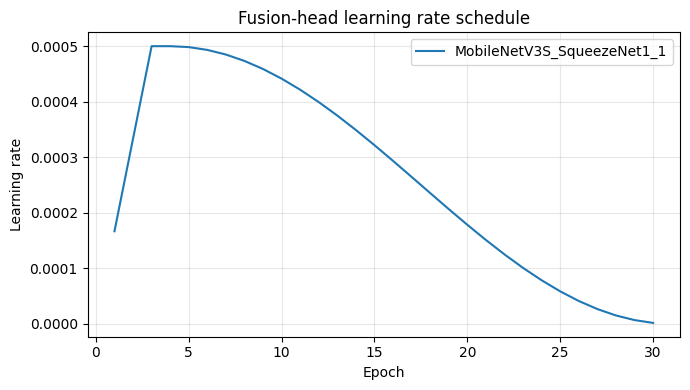

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in HYBRID_NAMES:
    h = all_hist[name]
    axes[0].plot(range(1, EPOCHS + 1), h.train_loss, label=name)
    axes[1].plot(range(1, EPOCHS + 1), h.train_acc,  label=name)
axes[0].set_title('Training loss'); axes[1].set_title('Training accuracy (augmented batches)')
for ax in axes: ax.set_xlabel('Epoch'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_training_loss_accuracy.png'), dpi=300, bbox_inches='tight')
plt.show()

# Learning-rate schedule (fusion head)
fig, ax = plt.subplots(figsize=(7, 4))
for name in HYBRID_NAMES:
    ax.plot(range(1, EPOCHS + 1), all_hist[name]['lr_head'], label=name)
ax.set_title('Fusion-head learning rate schedule')
ax.set_xlabel('Epoch'); ax.set_ylabel('Learning rate'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_learning_rate_schedule.png'), dpi=300, bbox_inches='tight')
plt.show()

## 9. Evaluation: classification reports and confusion matrices (train and test)

In [11]:
for name in HYBRID_NAMES:
    y_tr, p_tr, _, _ = all_train[name]; y_te, p_te, _, _ = all_test[name]
    print('=' * 72); print(f'{name} - TRAINING CLASSIFICATION REPORT'); print('=' * 72)
    print(classification_report(y_tr, p_tr, target_names=CLASS_NAMES, digits=4, zero_division=0))
    print('=' * 72); print(f'{name} - TESTING CLASSIFICATION REPORT'); print('=' * 72)
    print(classification_report(y_te, p_te, target_names=CLASS_NAMES, digits=4, zero_division=0))

MobileNetV3S_SqueezeNet1_1 - TRAINING CLASSIFICATION REPORT
                   precision    recall  f1-score   support

        Bird-drop     0.9954    0.9862    0.9908       436
            Clean     0.9897    0.9931    0.9914       578
            Dusty     1.0000    0.9980    0.9990       495
Electrical-damage     0.9868    1.0000    0.9933       224
  Physical-Damage     0.9951    0.9975    0.9963       809
     Snow-Covered     1.0000    0.9936    0.9968       312

         accuracy                         0.9947      2854
        macro avg     0.9945    0.9947    0.9946      2854
     weighted avg     0.9948    0.9947    0.9947      2854

MobileNetV3S_SqueezeNet1_1 - TESTING CLASSIFICATION REPORT
                   precision    recall  f1-score   support

        Bird-drop     0.9369    0.9541    0.9455       109
            Clean     0.9658    0.9724    0.9691       145
            Dusty     0.9746    0.9274    0.9504       124
Electrical-damage     1.0000    0.9821    0.9910   

### 9.2 Explainability visualisation: Grad-CAM

Grad-CAM is generated from the final convolutional feature map of the MobileNetV3-Small branch while differentiating the hybrid model's predicted class score. It is an interpretation aid, not an additional performance metric.

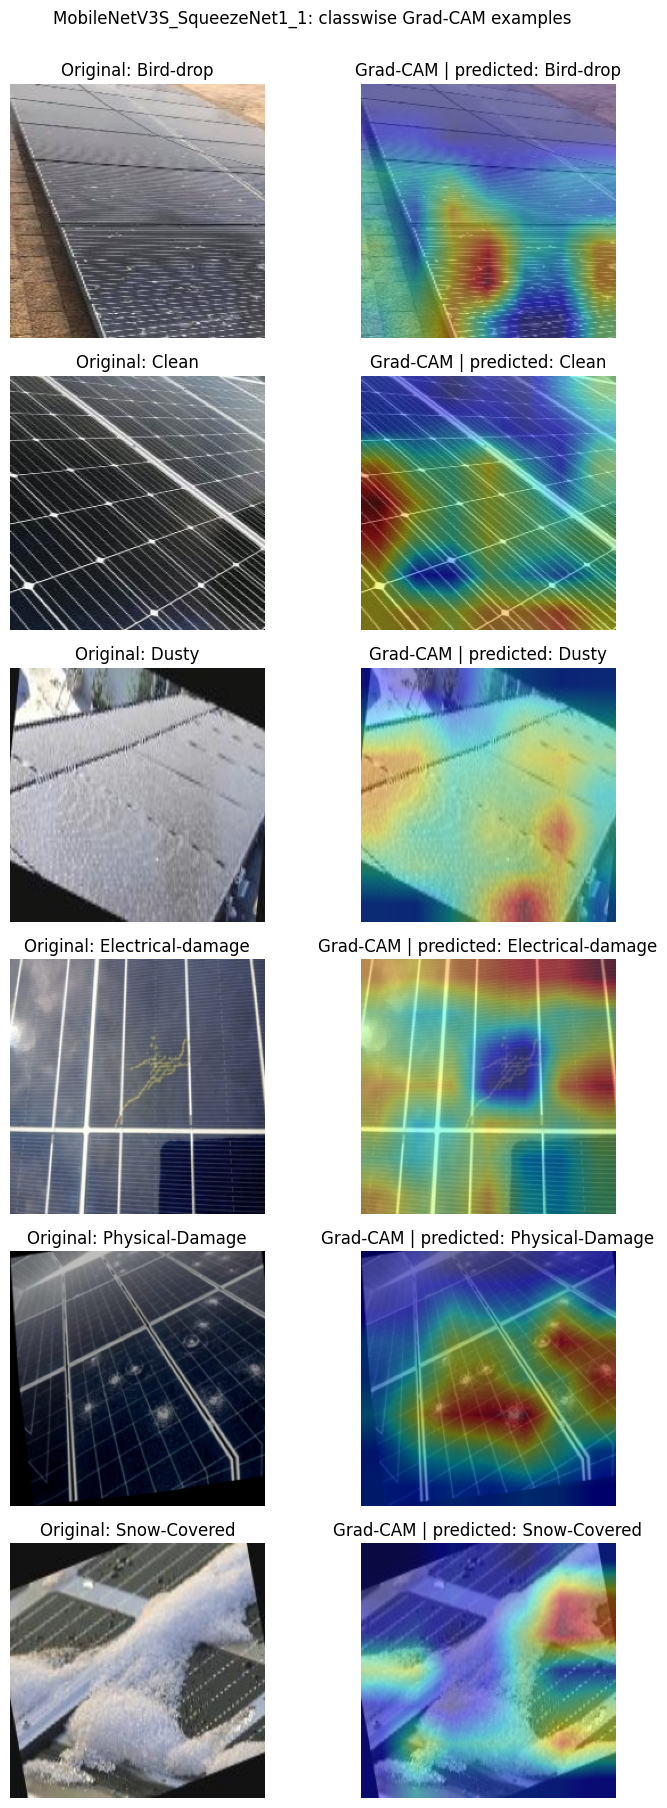

In [12]:

def make_hybrid_gradcam(model, image_tensor, target_class=None):
    """Grad-CAM on the final MobileNetV3-Small feature map in branch A."""
    model = model.cpu().eval()
    activations = {}
    target_layer = model.branch_a.features[-1]
    def capture_activation(module, inputs, output):
        activations['feature'] = output
    handle = target_layer.register_forward_hook(capture_activation)
    x = image_tensor.unsqueeze(0).cpu()
    try:
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(x)
            pred = int(logits.argmax(1).item())
            class_idx = pred if target_class is None else int(target_class)
            feature = activations['feature']
            gradient = torch.autograd.grad(logits[0, class_idx], feature, retain_graph=False)[0]
            weights = gradient.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu((weights * feature).sum(dim=1, keepdim=True))
            cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE),
                                                  mode='bilinear', align_corners=False)
            cam = cam[0, 0].detach().numpy()
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, pred
    finally:
        handle.remove()

for name in HYBRID_NAMES:
    model = trained[name].cpu().eval()
    fig, axes = plt.subplots(NUM_CLASSES, 2, figsize=(8, 3.0*NUM_CLASSES))
    for class_idx, class_name in enumerate(CLASS_NAMES):
        matches = np.where(test_labels == class_idx)[0]
        if len(matches) == 0:
            axes[class_idx, 0].axis('off'); axes[class_idx, 1].axis('off')
            continue
        dataset_idx = int(matches[0])
        image_tensor, true_label = test_ds[dataset_idx]
        cam, predicted = make_hybrid_gradcam(model, image_tensor)
        original = inv(image_tensor).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[class_idx, 0].imshow(original)
        axes[class_idx, 0].set_title(f'Original: {class_name}')
        axes[class_idx, 1].imshow(original)
        axes[class_idx, 1].imshow(cam, cmap='jet', alpha=.42)
        axes[class_idx, 1].set_title(f'Grad-CAM | predicted: {CLASS_NAMES[predicted]}')
        axes[class_idx, 0].axis('off'); axes[class_idx, 1].axis('off')
    plt.suptitle(f'{name}: classwise Grad-CAM examples', y=1.002)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'fig_{name}_gradcam_classwise.png'), dpi=300, bbox_inches='tight')
    plt.show()


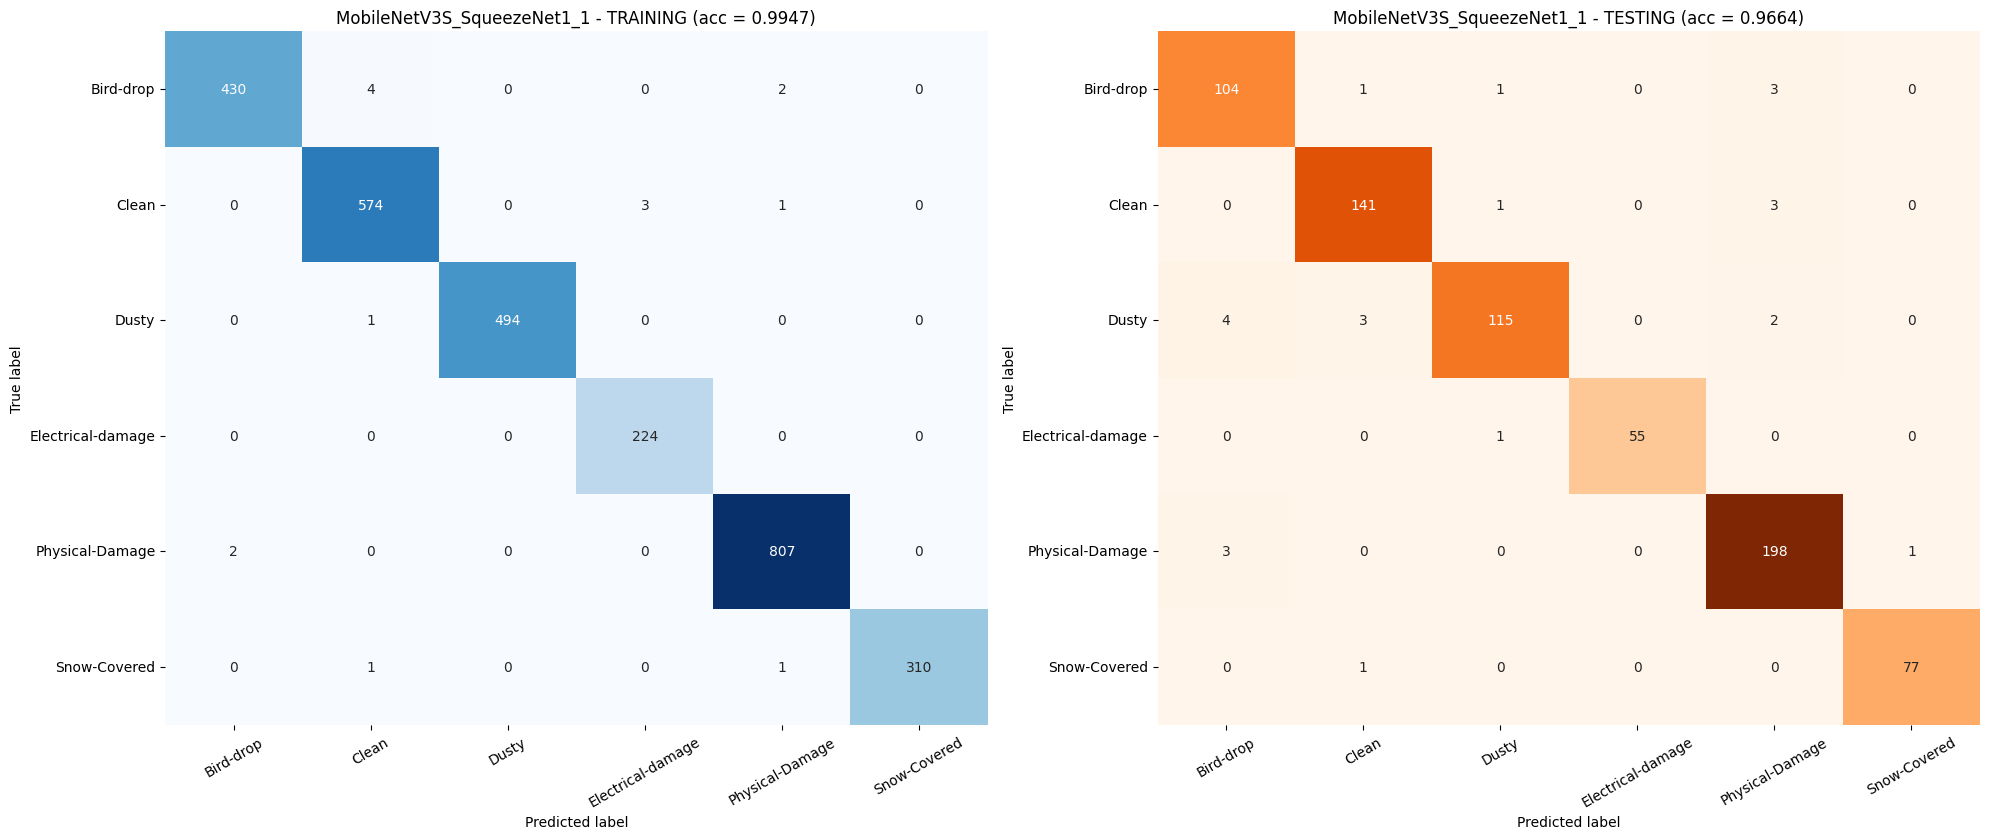

In [13]:
# Confusion matrices: counts
fig, axes = plt.subplots(len(HYBRID_NAMES), 2, figsize=(20, 8.5 * len(HYBRID_NAMES)), squeeze=False)
for r, name in enumerate(HYBRID_NAMES):
    for c, (split, store, cmap) in enumerate([('TRAINING', all_train, 'Blues'), ('TESTING', all_test, 'Oranges')]):
        y, p, _, cm = store[name]
        sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False, ax=axes[r, c],
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        axes[r, c].set_title(f'{name} - {split} (acc = {accuracy_score(y, p):.4f})')
        axes[r, c].set_xlabel('Predicted label'); axes[r, c].set_ylabel('True label')
        axes[r, c].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_confusion_matrices_train_test_counts.png'), dpi=300, bbox_inches='tight')
plt.show()

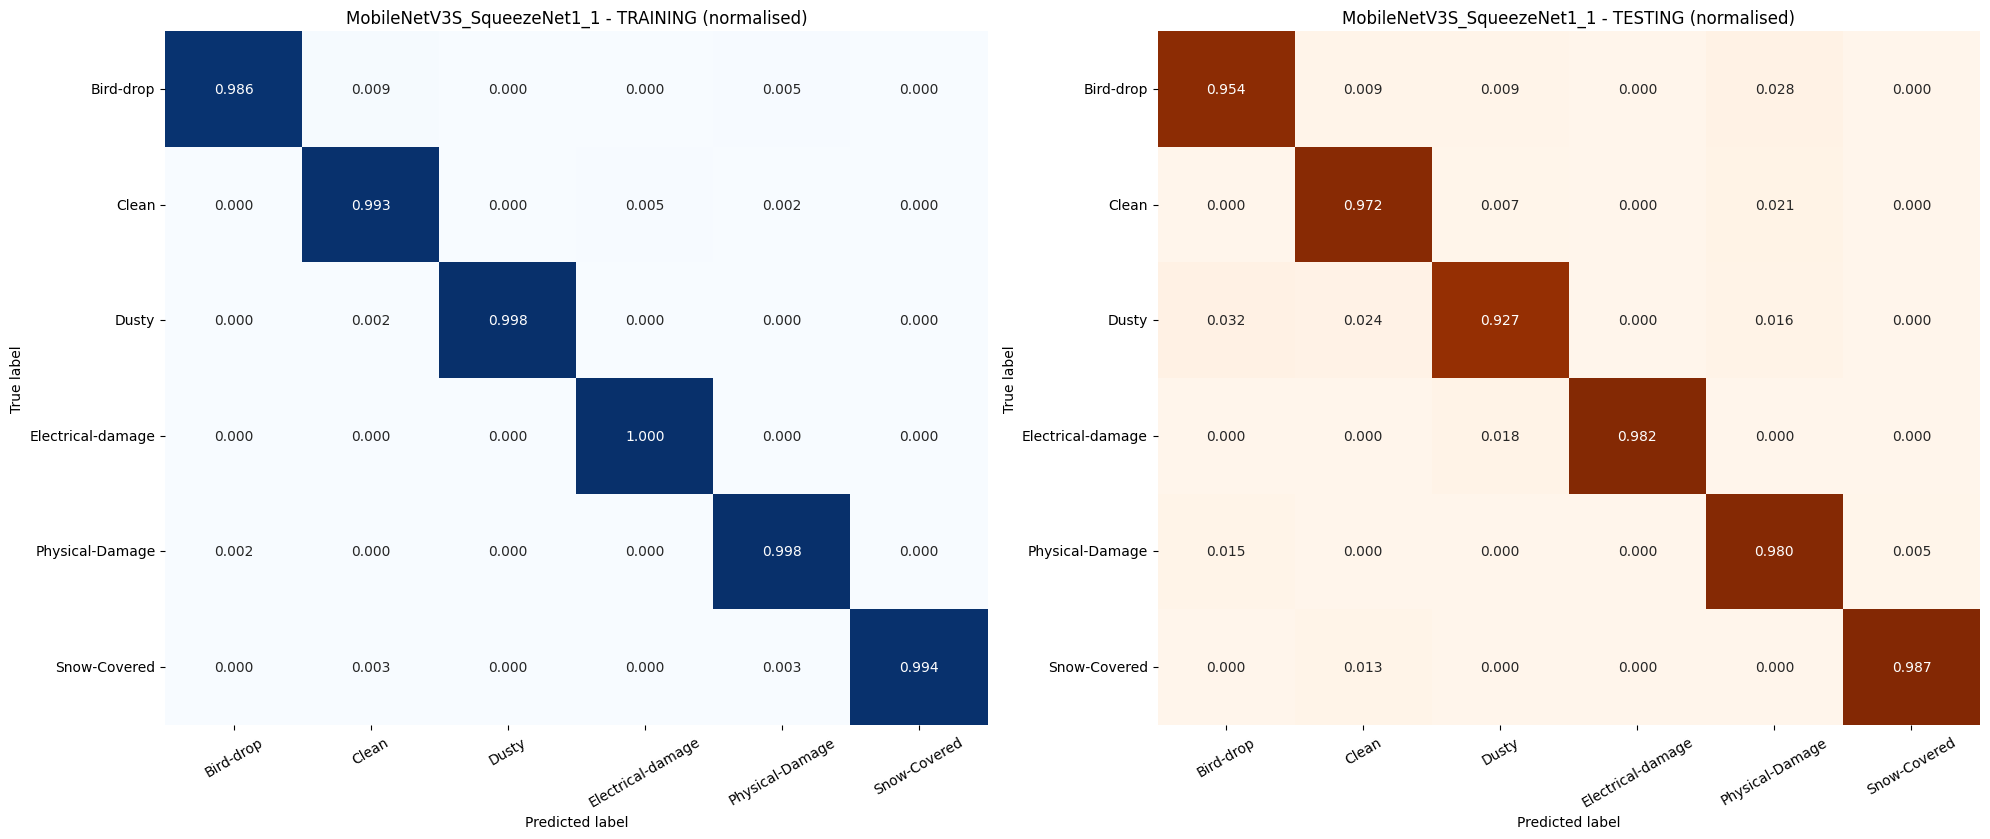

In [14]:
# Confusion matrices: row-normalised (per-class recall)
def norm_cm(cm): return cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, axes = plt.subplots(len(HYBRID_NAMES), 2, figsize=(20, 8.5 * len(HYBRID_NAMES)), squeeze=False)
for r, name in enumerate(HYBRID_NAMES):
    for c, (split, store, cmap) in enumerate([('TRAINING', all_train, 'Blues'), ('TESTING', all_test, 'Oranges')]):
        sns.heatmap(norm_cm(store[name][3]), annot=True, fmt='.3f', cmap=cmap, vmin=0, vmax=1, cbar=False,
                    ax=axes[r, c], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        axes[r, c].set_title(f'{name} - {split} (normalised)')
        axes[r, c].set_xlabel('Predicted label'); axes[r, c].set_ylabel('True label')
        axes[r, c].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_confusion_matrices_train_test_normalized.png'), dpi=300, bbox_inches='tight')
plt.show()

### 9.1 Classwise evaluation, ROC and precision-recall curves

Multiclass ROC and precision-recall curves are calculated one-vs-rest from the stored class probabilities. These are additional evaluation figures; the existing train/test split and final-epoch evaluation protocol remain unchanged.

,class,precision,recall,f1_score,support
0,Bird-drop,0.9369,0.9541,0.9455,109
1,Clean,0.9658,0.9724,0.9691,145
2,Dusty,0.9746,0.9274,0.9504,124
3,Electrical-damage,1.0000,0.9821,0.9910,56
4,Physical-Damage,0.9612,0.9802,0.9706,202
5,Snow-Covered,0.9872,0.9872,0.9872,78


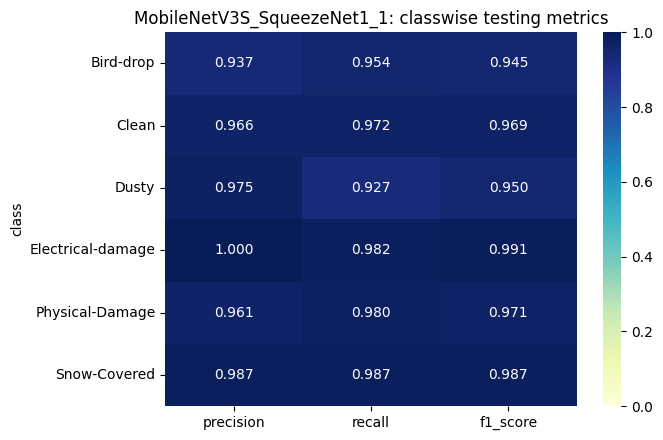

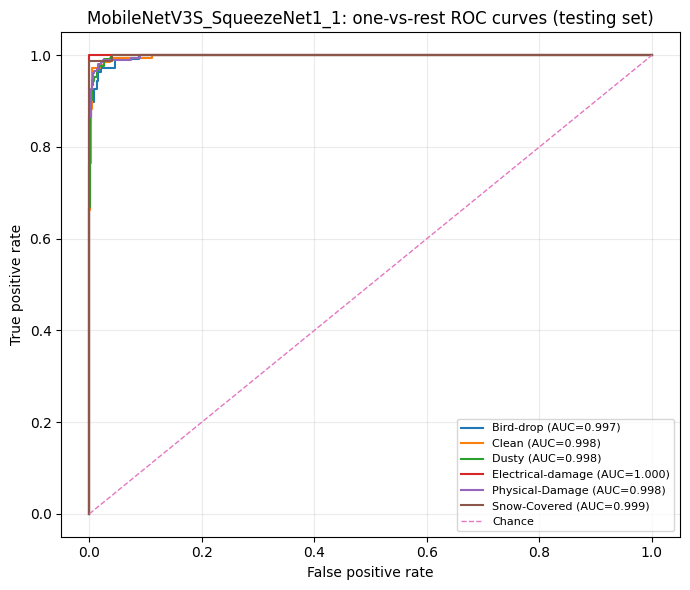

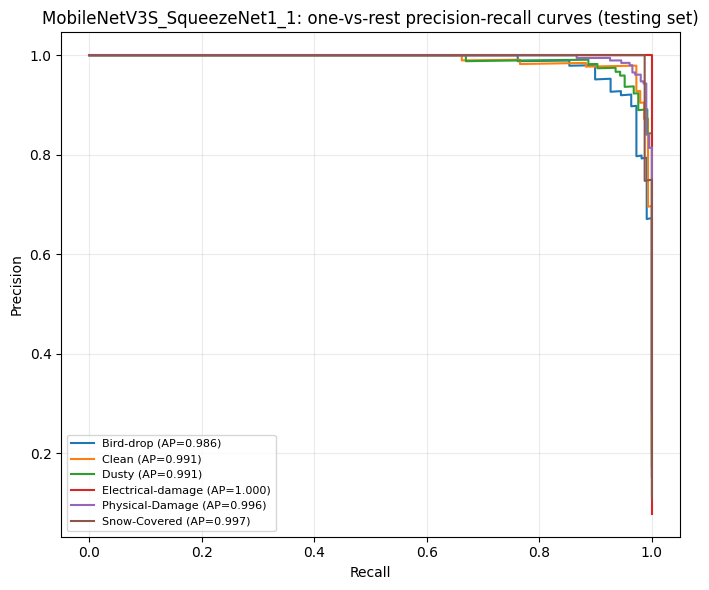

In [15]:

# Per-class precision, recall, F1 and support (testing set)
for name in HYBRID_NAMES:
    y_true, y_pred, y_prob, _ = all_test[name]
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    class_metrics = pd.DataFrame([
        {'class': cls, 'precision': report[cls]['precision'],
         'recall': report[cls]['recall'], 'f1_score': report[cls]['f1-score'],
         'support': int(report[cls]['support'])}
        for cls in CLASS_NAMES
    ])
    display(class_metrics.round(4))
    class_metrics.to_csv(os.path.join(FIG_DIR, f'table_{name}_classwise_test_metrics.csv'), index=False)

    # Classwise evaluation heatmap
    heat = class_metrics.set_index('class')[['precision', 'recall', 'f1_score']]
    plt.figure(figsize=(7, 4.5))
    sns.heatmap(heat, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1)
    plt.title(f'{name}: classwise testing metrics')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'fig_{name}_classwise_metrics_heatmap.png'), dpi=300, bbox_inches='tight')
    plt.show()

    y_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(7, 6))
    for class_idx, class_name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, class_idx], y_prob[:, class_idx])
        ax.plot(fpr, tpr, label=f'{class_name} (AUC={auc(fpr,tpr):.3f})')
    ax.plot([0,1], [0,1], linestyle='--', linewidth=1, label='Chance')
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'{name}: one-vs-rest ROC curves (testing set)')
    ax.grid(alpha=.25); ax.legend(fontsize=8, loc='lower right')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'fig_{name}_multiclass_roc.png'), dpi=300, bbox_inches='tight')
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 6))
    for class_idx, class_name in enumerate(CLASS_NAMES):
        precision, recall, _ = precision_recall_curve(y_bin[:, class_idx], y_prob[:, class_idx])
        ap = average_precision_score(y_bin[:, class_idx], y_prob[:, class_idx])
        ax.plot(recall, precision, label=f'{class_name} (AP={ap:.3f})')
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_title(f'{name}: one-vs-rest precision-recall curves (testing set)')
    ax.grid(alpha=.25); ax.legend(fontsize=8, loc='best')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'fig_{name}_precision_recall.png'), dpi=300, bbox_inches='tight')
    plt.show()


In [16]:
per_class = pd.DataFrame({n: all_results[n]['test_f1_per_class'] for n in HYBRID_NAMES}).T
print('Per-class test F1:'); display(per_class.round(4))

Per-class test F1:


,Bird-drop,Clean,Dusty,Electrical-damage,Physical-Damage,Snow-Covered
MobileNetV3S_SqueezeNet1_1,0.9455,0.9691,0.9504,0.991,0.9706,0.9872


## 10. Efficiency: latency measured on the same devices
Latency is measured with batch size 1, 15 warm-up runs and `LATENCY_RUNS` timed runs, on **both GPU and CPU**, so every model is compared on the same hardware. The single-model building blocks are benchmarked here as well (architecture only, random weights, since latency does not depend on the weights), so the hybrid-vs-parent latency comparison is fair and comes from the same session.

In [17]:
@torch.no_grad()
def latency_ms(m, device, runs=LATENCY_RUNS):
    m = copy.deepcopy(m).to(device).eval()
    x = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    for _ in range(15): m(x)
    if device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs): m(x)
    if device.type == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000.0

def count_params(m): return sum(p.numel() for p in m.parameters())

blocks = {
    'MobileNetV3_Small (single)': models.mobilenet_v3_small(weights=None, num_classes=NUM_CLASSES),
    'EfficientNet_Lite0 (single)': timm.create_model('tf_efficientnet_lite0', pretrained=False, num_classes=NUM_CLASSES),
    'SqueezeNet_1_1 (single)':     models.squeezenet1_1(weights=None, num_classes=NUM_CLASSES),
}
devices = [torch.device('cpu')] + ([torch.device('cuda')] if torch.cuda.is_available() else [])

lat_rows = []
for nm, m in {**{k: v for k, v in blocks.items()}, **trained}.items():
    row = {'model': nm, 'params_M': round(count_params(m) / 1e6, 3)}
    for d in devices:
        row[f'latency_{d.type}_ms'] = round(latency_ms(m, d), 3)
    lat_rows.append(row)
lat_df = pd.DataFrame(lat_rows)
display(lat_df)

for name in HYBRID_NAMES:
    for d in devices:
        all_results[name][f'latency_{d.type}_ms'] = float(lat_df.loc[lat_df.model == name, f'latency_{d.type}_ms'].iloc[0])

,model,params_M,latency_cpu_ms,latency_cuda_ms
0,MobileNetV3_Small (single),1.524,8.819,5.436
1,EfficientNet_Lite0 (single),3.379,26.957,5.685
2,SqueezeNet_1_1 (single),0.726,23.156,2.003
3,MobileNetV3S_SqueezeNet1_1,1.790,31.842,7.176


## 11. Comparison with the single models
The single-model accuracies below come from the single-model notebook run on the **same deduplicated 80/20 split and settings** (hard-coded reference values, clearly separated from this notebook's own results). Latencies for the single models are re-measured above, in this session.

,model,source,test_acc,test_macro_f1,test_misclassified,params_M,latency_cpu_ms,latency_cuda_ms
0,MobileNetV3S_SqueezeNet1_1,this notebook,0.9664,0.9689,24,1.790,31.842,7.176
1,MobileNetV3_Small (single),single-model notebook,0.9524,0.9551,34,1.524,8.819,5.436
2,EfficientNet_Lite0 (single),single-model notebook,0.9510,0.9499,35,3.379,26.957,5.685
3,SqueezeNet_1_1 (single),single-model notebook,0.9314,0.9302,49,0.726,23.156,2.003


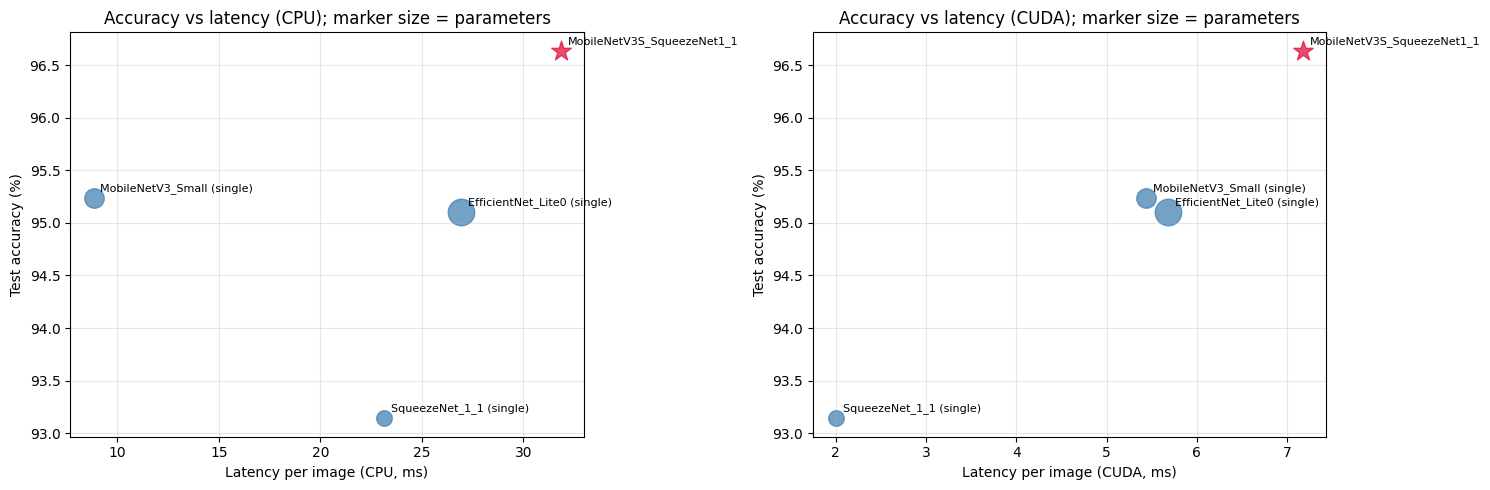

In [18]:
REFERENCE = {   # from the single-model notebook (same split, seed, preprocessing, epochs)
    'MobileNetV3_Small (single)':  {'test_acc': 0.9524, 'test_macro_f1': 0.9551, 'test_misclassified': 34},
    'EfficientNet_Lite0 (single)': {'test_acc': 0.9510, 'test_macro_f1': 0.9499, 'test_misclassified': 35},
    'SqueezeNet_1_1 (single)':     {'test_acc': 0.9314, 'test_macro_f1': 0.9302, 'test_misclassified': 49},
}
rows = []
for nm, r in REFERENCE.items():
    rows.append({'model': nm, 'source': 'single-model notebook', **r})
for nm in HYBRID_NAMES:
    r = all_results[nm]
    rows.append({'model': nm, 'source': 'this notebook', 'test_acc': r['test_acc'],
                 'test_macro_f1': r['test_macro_f1'], 'test_misclassified': r['test_misclassified']})
cmp_df = pd.DataFrame(rows).merge(lat_df, on='model', how='left').drop_duplicates('model')
display(cmp_df.sort_values('test_acc', ascending=False).reset_index(drop=True))

# Accuracy vs latency trade-off
fig, axes = plt.subplots(1, len(devices), figsize=(7.5 * len(devices), 5))
axes = np.atleast_1d(axes)
for ax, d in zip(axes, devices):
    col = f'latency_{d.type}_ms'
    for _, r in cmp_df.iterrows():
        is_h = r['source'] == 'this notebook'
        ax.scatter(r[col], 100 * r['test_acc'], s=60 + 90 * r['params_M'], alpha=.75,
                   marker='*' if is_h else 'o', color='crimson' if is_h else 'steelblue')
        ax.annotate(r['model'], (r[col], 100 * r['test_acc']), fontsize=8, xytext=(5, 5), textcoords='offset points')
    ax.set_xlabel(f'Latency per image ({d.type.upper()}, ms)'); ax.set_ylabel('Test accuracy (%)')
    ax.set_title(f'Accuracy vs latency ({d.type.upper()}); marker size = parameters'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [19]:
# McNemar's test requires predictions from two different hybrid models.
# Only H2 is retained in this notebook, so a pairwise McNemar test is not applicable.
print('McNemar test skipped: only one hybrid model (H2) is included.')


McNemar test skipped: only one hybrid model (H2) is included.


### 11.1 Architecture diagrams and tables: each single model and the trained hybrid

The next cell produces, for **every single model** (MobileNetV3-Small, EfficientNet-Lite0, SqueezeNet 1.1) and for the **hybrid model**, a stage-by-stage architecture **diagram** and a matching **table** (module type, layer details, output shape, parameters, share of parameters). A final summary table puts architecture, parameters, accuracy and latency of all models side by side.

Everything is read from the real model objects (module graph, forward hooks on a real forward pass, parameter counts):
- **Hybrid:** the final-epoch model trained in this notebook (`trained[...]`).
- **Single models:** built with the same constructors as the latency benchmark in Section 10. Their weights were trained in the single-model notebook; diagram, shapes and parameter counts do not depend on weight values. To load those trained weights, fill `SINGLE_CKPT_PATHS` at the top of the cell.

No model is trained, modified or re-evaluated here. Figures and CSV tables are saved in `research_figures/`.

MobileNetV3_Small (single)  |  architecture only (trained in single-model notebook)


,stage,module_type,details,output_shape,parameters,trainable_parameters,share_%
0,features.0,Conv2dNormActivation,"1 conv (3->16), 1 BN",16x112x112,464,464,0.03
1,features.1,InvertedResidual,"4 conv (16->16), 2 BN",16x56x56,744,744,0.05
2,features.2,InvertedResidual,"3 conv (16->24), 3 BN",24x28x28,3864,3864,0.25
3,features.3,InvertedResidual,"3 conv (24->24), 3 BN",24x28x28,5416,5416,0.36
4,features.4,InvertedResidual,"5 conv (24->40), 3 BN",40x14x14,13736,13736,0.90
5,features.5,InvertedResidual,"5 conv (40->40), 3 BN",40x14x14,57264,57264,3.76
6,features.6,InvertedResidual,"5 conv (40->40), 3 BN",40x14x14,57264,57264,3.76
7,features.7,InvertedResidual,"5 conv (40->48), 3 BN",48x14x14,21968,21968,1.44
8,features.8,InvertedResidual,"5 conv (48->48), 3 BN",48x14x14,29800,29800,1.96
9,features.9,InvertedResidual,"5 conv (48->96), 3 BN",96x7x7,91848,91848,6.03


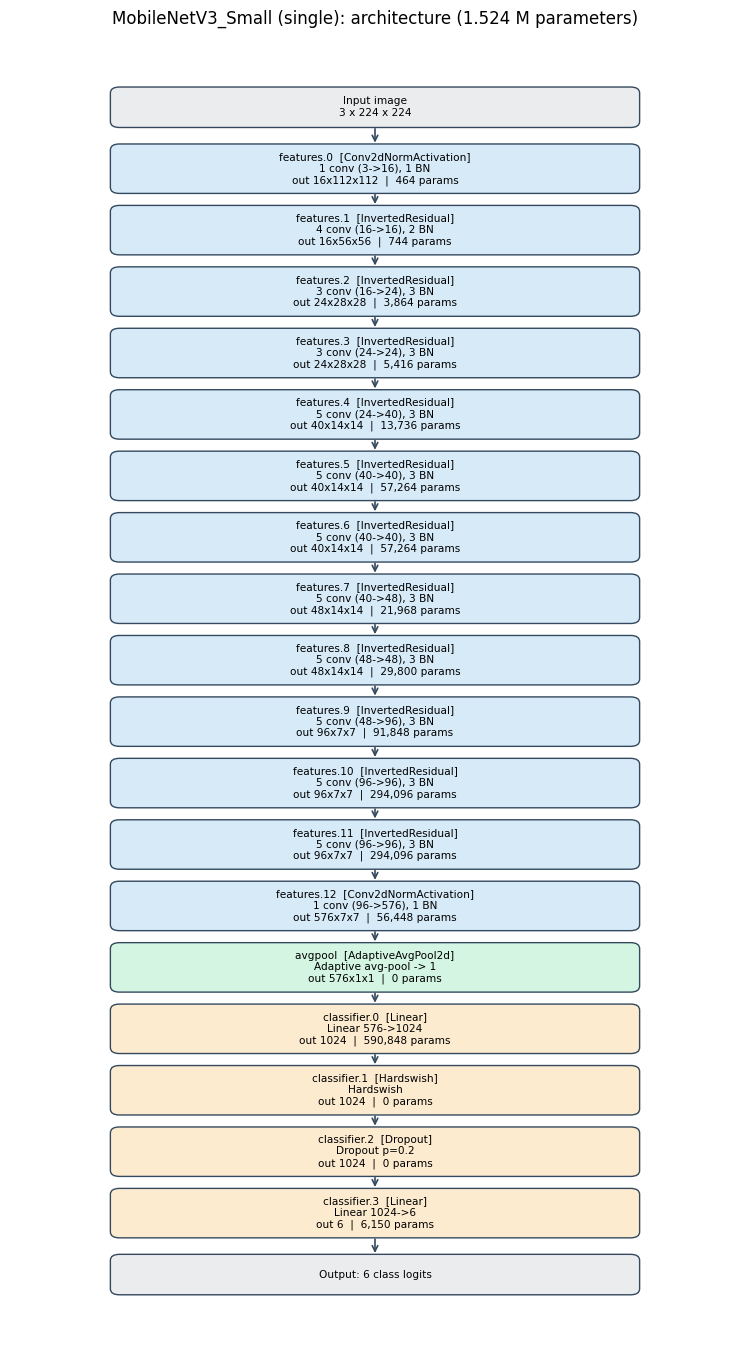

EfficientNet_Lite0 (single)  |  architecture only (trained in single-model notebook)


,stage,module_type,details,output_shape,parameters,trainable_parameters,share_%
0,conv_stem,Conv2dSame,"Conv 3->32, k=3, s=2",32x112x112,864,864,0.03
1,bn1,BatchNormAct2d,BatchNormAct2d,32x112x112,64,64,0.00
2,blocks.0,Sequential,"2 conv (32->16), 2 BN",16x112x112,896,896,0.03
3,blocks.1,Sequential,"6 conv (16->24), 6 BN",24x56x56,13968,13968,0.41
4,blocks.2,Sequential,"6 conv (24->40), 6 BN",40x28x28,39712,39712,1.18
5,blocks.3,Sequential,"9 conv (40->80), 9 BN",80x14x14,198480,198480,5.87
6,blocks.4,Sequential,"9 conv (80->112), 9 BN",112x14x14,446784,446784,13.22
7,blocks.5,Sequential,"12 conv (112->192), 12 BN",192x7x7,1652640,1652640,48.91
8,blocks.6,Sequential,"3 conv (192->320), 3 BN",320x7x7,605440,605440,17.92
9,conv_head,Conv2d,"Conv 320->1280, k=1, s=1",1280x7x7,409600,409600,12.12


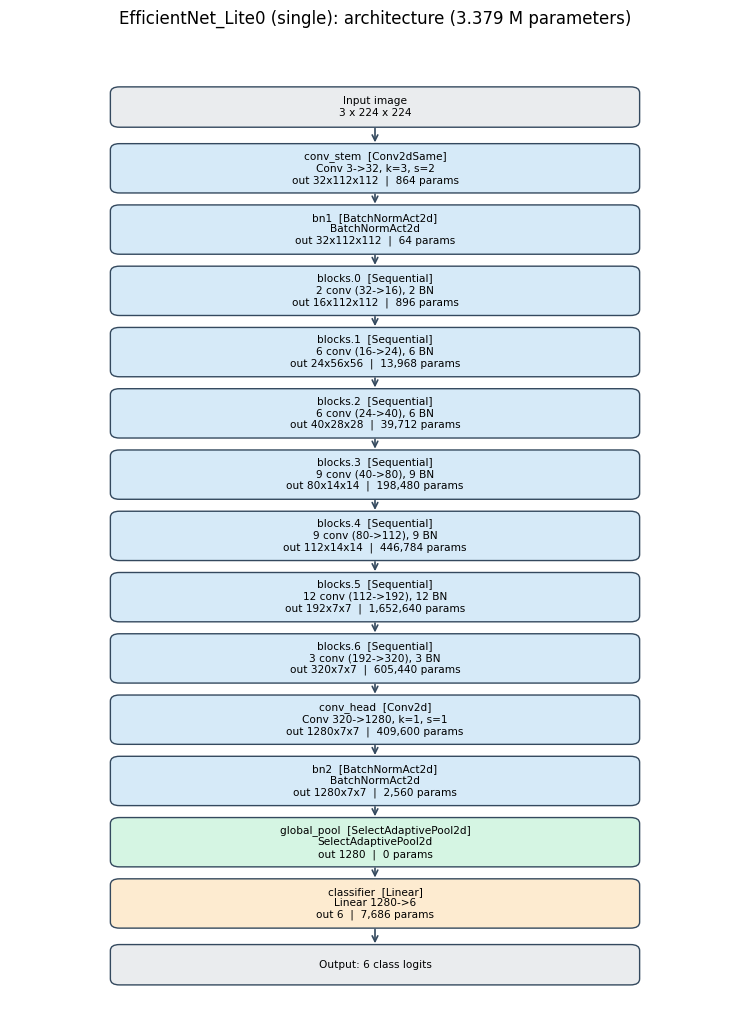

SqueezeNet_1_1 (single)  |  architecture only (trained in single-model notebook)


,stage,module_type,details,output_shape,parameters,trainable_parameters,share_%
0,features.0,Conv2d,"Conv 3->64, k=3, s=2",64x111x111,1792,1792,0.25
1,features.1,ReLU,ReLU,64x111x111,0,0,0.00
2,features.2,MaxPool2d,Max-pool,64x55x55,0,0,0.00
3,features.3,Fire,3 conv (64->64),128x55x55,11408,11408,1.57
4,features.4,Fire,3 conv (128->64),128x55x55,12432,12432,1.71
5,features.5,MaxPool2d,Max-pool,128x27x27,0,0,0.00
6,features.6,Fire,3 conv (128->128),256x27x27,45344,45344,6.25
7,features.7,Fire,3 conv (256->128),256x27x27,49440,49440,6.81
8,features.8,MaxPool2d,Max-pool,256x13x13,0,0,0.00
9,features.9,Fire,3 conv (256->192),384x13x13,104880,104880,14.45


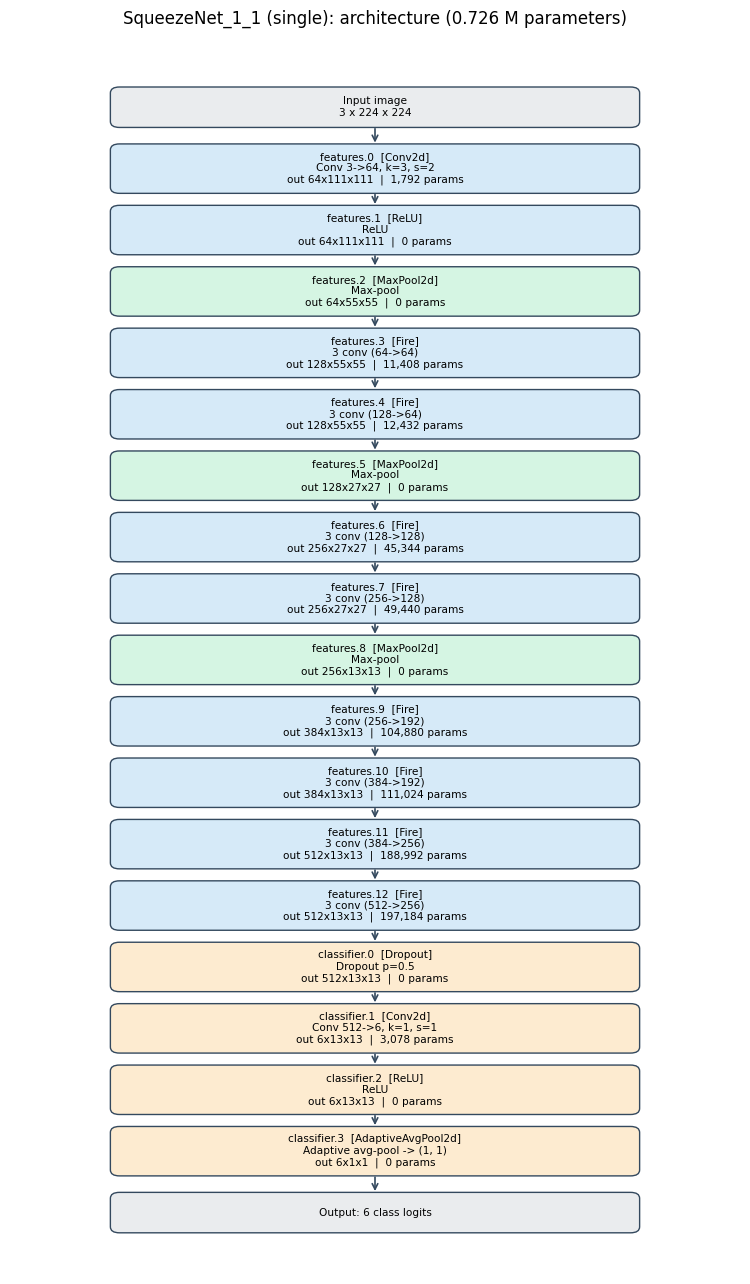

MobileNetV3S_SqueezeNet1_1  |  final-epoch model trained in this notebook


,part,stage,module_type,details,output_shape,parameters,trainable_parameters,share_%
0,branch A (MobileNetV3-Small),branch_a.features.0,Conv2dNormActivation,"1 conv (3->16), 1 BN",16x112x112,464,464,0.03
1,branch A (MobileNetV3-Small),branch_a.features.1,InvertedResidual,"4 conv (16->16), 2 BN",16x56x56,744,744,0.04
2,branch A (MobileNetV3-Small),branch_a.features.2,InvertedResidual,"3 conv (16->24), 3 BN",24x28x28,3864,3864,0.22
3,branch A (MobileNetV3-Small),branch_a.features.3,InvertedResidual,"3 conv (24->24), 3 BN",24x28x28,5416,5416,0.30
4,branch A (MobileNetV3-Small),branch_a.features.4,InvertedResidual,"5 conv (24->40), 3 BN",40x14x14,13736,13736,0.77
5,branch A (MobileNetV3-Small),branch_a.features.5,InvertedResidual,"5 conv (40->40), 3 BN",40x14x14,57264,57264,3.20
6,branch A (MobileNetV3-Small),branch_a.features.6,InvertedResidual,"5 conv (40->40), 3 BN",40x14x14,57264,57264,3.20
7,branch A (MobileNetV3-Small),branch_a.features.7,InvertedResidual,"5 conv (40->48), 3 BN",48x14x14,21968,21968,1.23
8,branch A (MobileNetV3-Small),branch_a.features.8,InvertedResidual,"5 conv (48->48), 3 BN",48x14x14,29800,29800,1.67
9,branch A (MobileNetV3-Small),branch_a.features.9,InvertedResidual,"5 conv (48->96), 3 BN",96x7x7,91848,91848,5.13


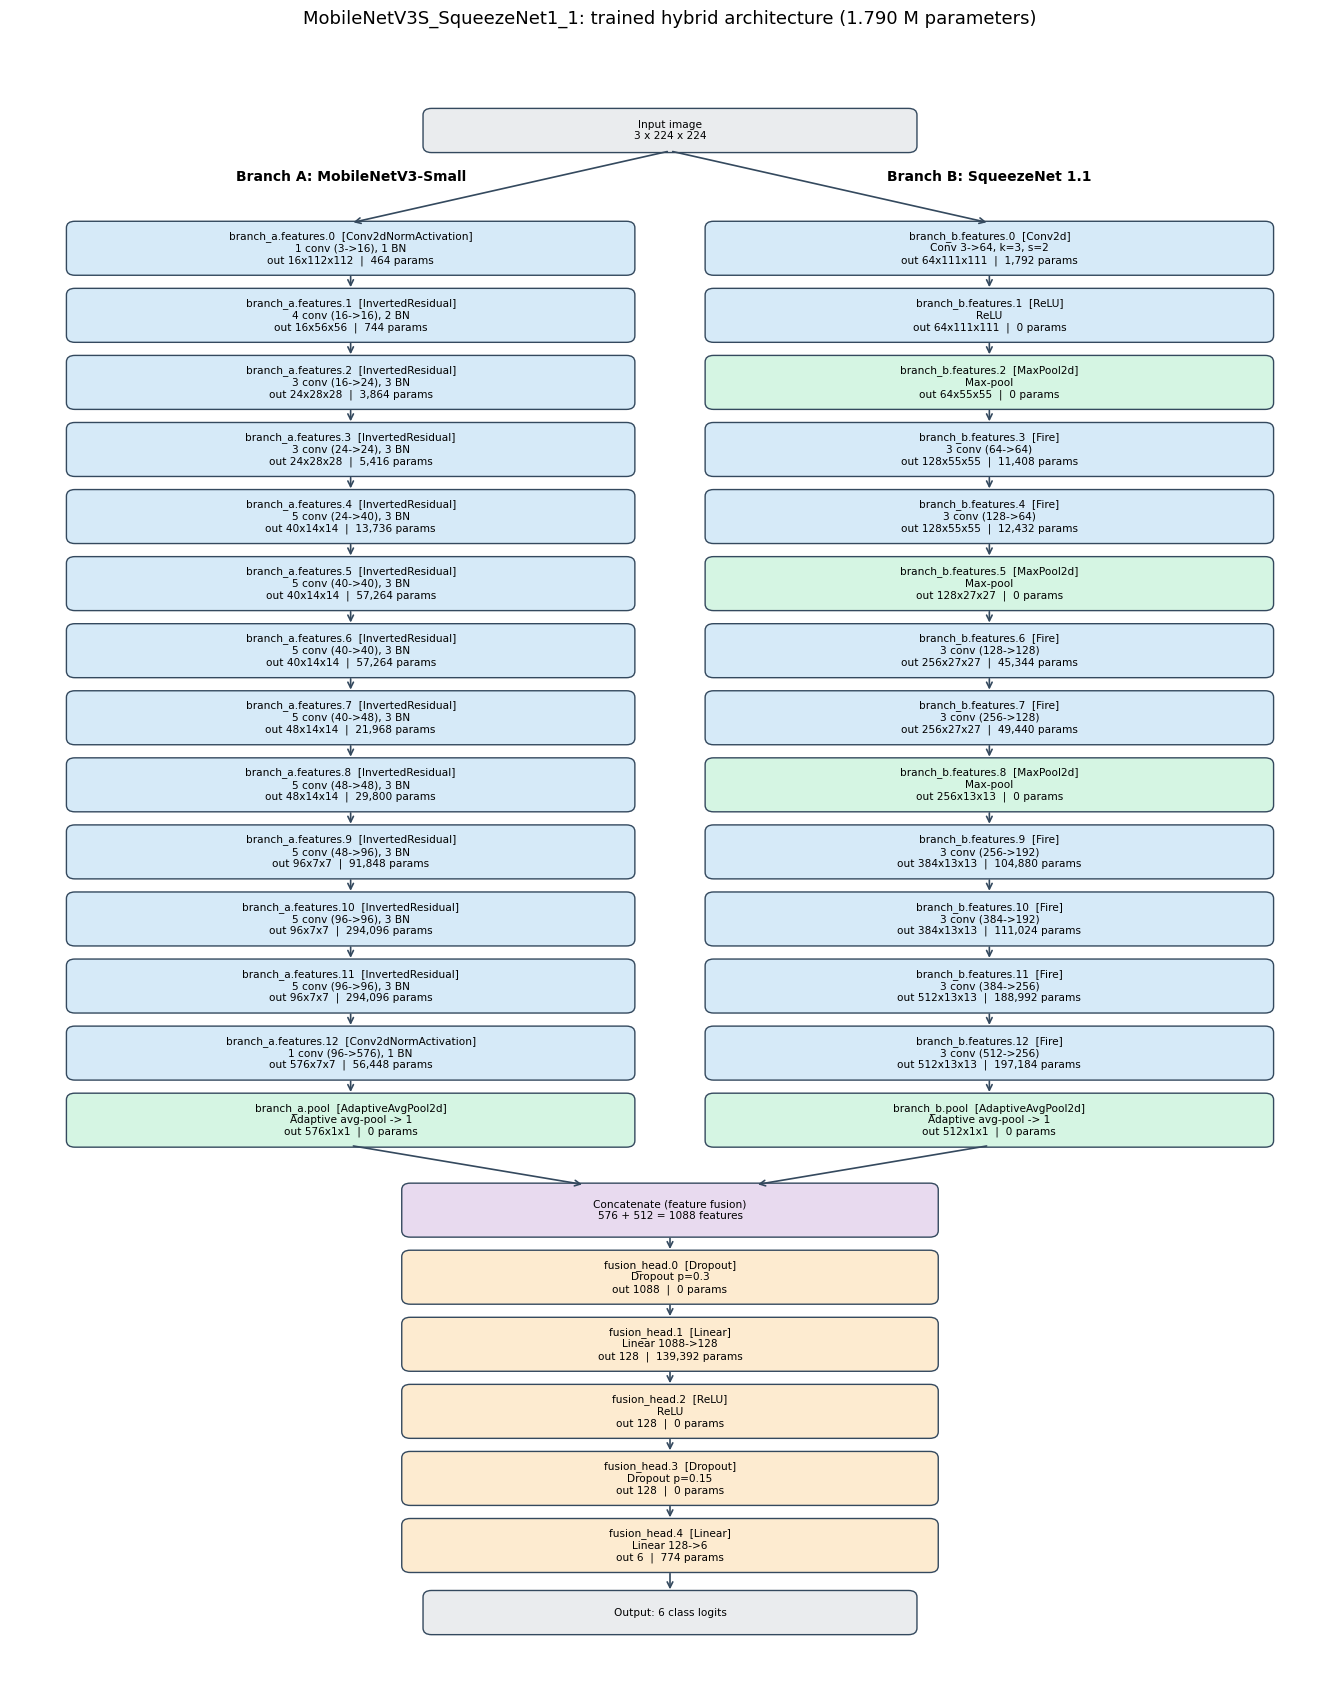

,model,type,weights,params_M,fp32_size_MB,stages,conv_layers,bn_layers,fc_layers,input,output,test_acc,test_macro_f1,test_misclassified,latency_cpu_ms,latency_cuda_ms
0,MobileNetV3_Small (single),single,architecture only (trained in single-model not...,1.524,5.81,18,52,34,2,3 x 224 x 224,"(6,)",0.9524,0.9551,34,8.819,5.436
1,EfficientNet_Lite0 (single),single,architecture only (trained in single-model not...,3.379,12.89,13,49,49,1,3 x 224 x 224,"(6,)",0.9510,0.9499,35,26.957,5.685
2,SqueezeNet_1_1 (single),single,architecture only (trained in single-model not...,0.726,2.77,17,26,0,0,3 x 224 x 224,"(6,)",0.9314,0.9302,49,23.156,2.003
3,MobileNetV3S_SqueezeNet1_1,hybrid,final-epoch model trained in this notebook,1.790,6.83,33,77,34,2,3 x 224 x 224,"(6,)",0.9664,0.9689,24,31.842,7.176


Saved architecture diagrams and tables to: /kaggle/working/research_figures


In [20]:
# ---------------------------------------------------------------------------------------------
# Architecture diagrams and tables for every single model and for the TRAINED hybrid model.
# Everything below is read from the real model objects (module graph, forward hooks, parameter
# counts). No model is trained, modified or re-evaluated here.
#   * Hybrid  : the final-epoch model trained in this notebook (trained[...]).
#   * Singles : built with the same constructors used for the latency benchmark in Section 10.
#               Their weights were trained in the single-model notebook (not available here), but
#               architecture, shapes and parameter counts do not depend on the weight values.
#               Optionally point SINGLE_CKPT_PATHS to those checkpoints to load the trained weights.
# ---------------------------------------------------------------------------------------------
import re
from matplotlib.patches import FancyBboxPatch

SINGLE_CKPT_PATHS = {   # optional, e.g. {'MobileNetV3_Small (single)': '/kaggle/input/.../MobileNetV3_Small_80_20.pth'}
    # 'MobileNetV3_Small (single)':  None,
    # 'EfficientNet_Lite0 (single)': None,
    # 'SqueezeNet_1_1 (single)':     None,
}

def _slug(s): return re.sub(r'[^A-Za-z0-9]+', '_', s).strip('_')

def _expand_stages(model, prefix=''):
    """Top-level children of a model; 'features', 'blocks' and 'classifier' containers are opened up."""
    stages = []
    for n, m in model.named_children():
        if n in ('features', 'blocks', 'classifier', 'fusion_head') and isinstance(m, nn.Sequential):
            for i, c in enumerate(m):
                stages.append((f'{prefix}{n}.{i}', c))
        else:
            stages.append((f'{prefix}{n}', m))
    return stages

def _describe(m):
    convs = [x for x in m.modules() if isinstance(x, nn.Conv2d)]
    bns   = [x for x in m.modules() if isinstance(x, nn.BatchNorm2d)]
    lins  = [x for x in m.modules() if isinstance(x, nn.Linear)]
    if isinstance(m, nn.Conv2d):
        return f'Conv {m.in_channels}->{m.out_channels}, k={m.kernel_size[0]}, s={m.stride[0]}'
    if isinstance(m, nn.Linear):
        return f'Linear {m.in_features}->{m.out_features}'
    if isinstance(m, nn.Dropout):
        return f'Dropout p={m.p:g}'
    if isinstance(m, nn.AdaptiveAvgPool2d):
        return f'Adaptive avg-pool -> {m.output_size}'
    if isinstance(m, nn.MaxPool2d):
        return 'Max-pool'
    if len(convs) == 0 and len(lins) == 0:
        return type(m).__name__
    parts = []
    if convs: parts.append(f'{len(convs)} conv ({convs[0].in_channels}->{convs[-1].out_channels})')
    if bns:   parts.append(f'{len(bns)} BN')
    if lins:  parts.append(f'{len(lins)} FC ({lins[0].in_features}->{lins[-1].out_features})')
    return ', '.join(parts)

def inspect_stages(model, prefix=''):
    """Return a list of dicts (one per stage) with real output shapes from a hooked forward pass."""
    stages = _expand_stages(model, prefix)
    shapes, hooks = {}, []
    for nm, mod in stages:
        def _hook(module, inputs, output, nm=nm):
            o = output[0] if isinstance(output, (tuple, list)) else output
            shapes[nm] = tuple(o.shape[1:])
        hooks.append(mod.register_forward_hook(_hook))
    return stages, shapes, hooks

def stage_table(stages, shapes):
    rows = []
    for nm, mod in stages:
        p  = sum(x.numel() for x in mod.parameters())
        tp = sum(x.numel() for x in mod.parameters() if x.requires_grad)
        rows.append({'stage': nm, 'module_type': type(mod).__name__, 'details': _describe(mod),
                     'output_shape': 'x'.join(map(str, shapes.get(nm, ()))) or '-',
                     'parameters': p, 'trainable_parameters': tp})
    df = pd.DataFrame(rows)
    df['share_%'] = (100 * df.parameters / max(df.parameters.sum(), 1)).round(2)
    return df

def _box_color(name, mtype):
    n = name.lower()
    if 'fusion' in n or 'classifier' in n or n in ('fc', 'head') or n.endswith('.classifier'):
        return '#fdebd0'          # classifier / head
    if 'pool' in n or 'pool' in mtype.lower():
        return '#d5f5e3'          # pooling
    return '#d6eaf8'              # feature extractor

def _draw_box(ax, x, y, text, color, w=4.6, h=0.62, fs=7.6):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle='round,pad=0.02,rounding_size=0.08',
                                facecolor=color, edgecolor='#34495e', linewidth=1.0))
    ax.text(x, y, text, ha='center', va='center', fontsize=fs)

def _arrow(ax, x0, y0, x1, y1):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='->', lw=1.2, color='#34495e'))

def _label(row, with_params=True):
    s = f"{row['stage']}  [{row['module_type']}]\n{row['details']}\nout {row['output_shape']}"
    return s + (f"  |  {row['parameters']:,} params" if with_params else '')

def draw_single_diagram(title, tbl, in_shape, save_name):
    n, step = len(tbl), 0.82
    fig, ax = plt.subplots(figsize=(7.6, 0.62 * n + 2.4))
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-(n + 2) * step, 1.0); ax.axis('off')
    y = 0.0
    _draw_box(ax, 0, y, f'Input image\n{in_shape}', '#eaecee', h=0.5)
    prev = y
    for _, r in tbl.iterrows():
        y -= step
        _arrow(ax, 0, prev - 0.25 if prev == 0 else prev - 0.31, 0, y + 0.31)
        _draw_box(ax, 0, y, _label(r), _box_color(r['stage'], r['module_type']))
        prev = y
    y -= step
    _arrow(ax, 0, prev - 0.31, 0, y + 0.25)
    _draw_box(ax, 0, y, f'Output: {NUM_CLASSES} class logits', '#eaecee', h=0.5)
    ax.set_title(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, save_name), dpi=300, bbox_inches='tight')
    plt.show()

def draw_hybrid_diagram(title, tbl_a, tbl_b, tbl_h, dim_a, dim_b, in_shape, save_name):
    na, nb, nh = len(tbl_a), len(tbl_b), len(tbl_h)
    step = 0.82
    top = max(na, nb)
    fig, ax = plt.subplots(figsize=(13.5, 0.62 * (top + nh) + 5.2))
    ax.set_xlim(-6.2, 6.2); ax.set_ylim(-(top + nh + 5) * step, 1.2); ax.axis('off')
    xa, xb = -3.0, 3.0
    y0 = 0.0
    _draw_box(ax, 0, y0, f'Input image\n{in_shape}', '#eaecee', h=0.5)
    ax.text(xa, y0 - 0.62, 'Branch A: MobileNetV3-Small', ha='center', fontsize=10, fontweight='bold')
    ax.text(xb, y0 - 0.62, 'Branch B: SqueezeNet 1.1',   ha='center', fontsize=10, fontweight='bold')
    for tbl, x in ((tbl_a, xa), (tbl_b, xb)):
        y, prev = y0 - 0.62, None
        for _, r in tbl.iterrows():
            y -= step
            if prev is None: _arrow(ax, 0, y0 - 0.25, x, y + 0.31)
            else:            _arrow(ax, x, prev - 0.31, x, y + 0.31)
            _draw_box(ax, x, y, _label(r), _box_color(r['stage'], r['module_type']), w=5.3)
            prev = y
        if x == xa: ya, last_a = y, prev
        else:       yb, last_b = y, prev
    ycat = min(ya, yb) - 1.1
    _draw_box(ax, 0, ycat, f'Concatenate (feature fusion)\n{dim_a} + {dim_b} = {dim_a + dim_b} features', '#e8daef', w=5.0)
    _arrow(ax, xa, last_a - 0.31, -0.8, ycat + 0.31)
    _arrow(ax, xb, last_b - 0.31,  0.8, ycat + 0.31)
    y, prev = ycat, ycat
    for _, r in tbl_h.iterrows():
        y -= step
        _arrow(ax, 0, prev - 0.31, 0, y + 0.31)
        _draw_box(ax, 0, y, _label(r), '#fdebd0', w=5.0)
        prev = y
    y -= step
    _arrow(ax, 0, prev - 0.31, 0, y + 0.25)
    _draw_box(ax, 0, y, f'Output: {NUM_CLASSES} class logits', '#eaecee', h=0.5)
    ax.set_ylim(y - 0.8, 1.2)
    ax.set_title(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, save_name), dpi=300, bbox_inches='tight')
    plt.show()

# ----------------------------- models to inspect -----------------------------
single_models = {
    'MobileNetV3_Small (single)':  models.mobilenet_v3_small(weights=None, num_classes=NUM_CLASSES),
    'EfficientNet_Lite0 (single)': timm.create_model('tf_efficientnet_lite0', pretrained=False, num_classes=NUM_CLASSES),
    'SqueezeNet_1_1 (single)':     models.squeezenet1_1(weights=None, num_classes=NUM_CLASSES),
}
weight_state = {}
for nm, m in single_models.items():
    ck = SINGLE_CKPT_PATHS.get(nm)
    if ck and os.path.exists(ck):
        sd = torch.load(ck, map_location='cpu')
        sd = sd.get('model_state_dict', sd)
        m.load_state_dict(sd)
        weight_state[nm] = 'trained weights loaded from checkpoint'
    else:
        weight_state[nm] = 'architecture only (trained in single-model notebook)'
for nm in HYBRID_NAMES:
    weight_state[nm] = 'final-epoch model trained in this notebook'

arch_rows, stage_tables = [], {}
x_in = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
IN_SHAPE = f'3 x {IMAGE_SIZE} x {IMAGE_SIZE}'

# ----------------------------- single models -----------------------------
for nm, model_ in single_models.items():
    m = copy.deepcopy(model_).cpu().eval()
    stages, shapes, hooks = inspect_stages(m)
    with torch.no_grad(): logits = m(x_in)
    for h in hooks: h.remove()
    tbl = stage_table(stages, shapes)
    stage_tables[nm] = tbl
    print('=' * 100); print(f'{nm}  |  {weight_state[nm]}'); print('=' * 100)
    display(tbl)
    tbl.to_csv(os.path.join(FIG_DIR, f'table_arch_{_slug(nm)}_stages.csv'), index=False)
    draw_single_diagram(f'{nm}: architecture ({sum(p.numel() for p in m.parameters())/1e6:.3f} M parameters)',
                        tbl, IN_SHAPE, f'fig_arch_{_slug(nm)}.png')
    mods = list(m.modules())
    arch_rows.append({'model': nm, 'type': 'single', 'weights': weight_state[nm],
                      'params_M': round(sum(p.numel() for p in m.parameters()) / 1e6, 3),
                      'fp32_size_MB': round(sum(p.numel() for p in m.parameters()) * 4 / 2**20, 2),
                      'stages': len(tbl), 'conv_layers': sum(isinstance(x, nn.Conv2d) for x in mods),
                      'bn_layers': sum(isinstance(x, nn.BatchNorm2d) for x in mods),
                      'fc_layers': sum(isinstance(x, nn.Linear) for x in mods),
                      'input': IN_SHAPE, 'output': tuple(logits.shape[1:])})

# ----------------------------- trained hybrid model(s) -----------------------------
for nm in HYBRID_NAMES:
    m = copy.deepcopy(trained[nm]).cpu().eval()           # the actual trained model
    st_a, sh_a, hk_a = inspect_stages(m.branch_a, 'branch_a.')
    st_b, sh_b, hk_b = inspect_stages(m.branch_b, 'branch_b.')
    st_h = [(f'fusion_head.{i}', c) for i, c in enumerate(m.fusion_head)]
    sh_h = {}
    hk_h = [c.register_forward_hook(lambda mod, i, o, k=f'fusion_head.{i}': sh_h.__setitem__(k, tuple(o.shape[1:])))
            for i, c in enumerate(m.fusion_head)]
    with torch.no_grad(): logits = m(x_in)
    for h in hk_a + hk_b + hk_h: h.remove()
    tbl_a, tbl_b, tbl_h = stage_table(st_a, sh_a), stage_table(st_b, sh_b), stage_table(st_h, sh_h)
    # branch-level pooling/flatten dims taken from the real model
    dim_a, dim_b = m.branch_a.out_dim, m.branch_b.out_dim
    assert m.fusion_head[1].in_features == dim_a + dim_b
    full = pd.concat([tbl_a.assign(part='branch A (MobileNetV3-Small)'),
                      tbl_b.assign(part='branch B (SqueezeNet 1.1)'),
                      tbl_h.assign(part='fusion head')], ignore_index=True)
    full = full[['part', 'stage', 'module_type', 'details', 'output_shape', 'parameters', 'trainable_parameters']]
    full['share_%'] = (100 * full.parameters / full.parameters.sum()).round(2)
    stage_tables[nm] = full
    print('=' * 100); print(f'{nm}  |  {weight_state[nm]}'); print('=' * 100)
    display(full)
    full.to_csv(os.path.join(FIG_DIR, f'table_arch_{_slug(nm)}_stages.csv'), index=False)
    draw_hybrid_diagram(f'{nm}: trained hybrid architecture ({sum(p.numel() for p in m.parameters())/1e6:.3f} M parameters)',
                        tbl_a, tbl_b, tbl_h, dim_a, dim_b, IN_SHAPE, f'fig_arch_{_slug(nm)}_trained.png')
    mods = list(m.modules())
    arch_rows.append({'model': nm, 'type': 'hybrid', 'weights': weight_state[nm],
                      'params_M': round(sum(p.numel() for p in m.parameters()) / 1e6, 3),
                      'fp32_size_MB': round(sum(p.numel() for p in m.parameters()) * 4 / 2**20, 2),
                      'stages': len(full), 'conv_layers': sum(isinstance(x, nn.Conv2d) for x in mods),
                      'bn_layers': sum(isinstance(x, nn.BatchNorm2d) for x in mods),
                      'fc_layers': sum(isinstance(x, nn.Linear) for x in mods),
                      'input': IN_SHAPE, 'output': tuple(logits.shape[1:])})

# ----------------------------- summary table: architecture + results of every model -----------------------------
arch_df = pd.DataFrame(arch_rows)
perf = []
for nm in arch_df.model:
    if nm in REFERENCE:
        perf.append({'model': nm, **REFERENCE[nm]})                      # single-model notebook values (same split/settings)
    else:
        r = all_results[nm]                                              # this notebook's trained hybrid
        perf.append({'model': nm, 'test_acc': r['test_acc'], 'test_macro_f1': r['test_macro_f1'],
                     'test_misclassified': r['test_misclassified']})
summary_arch = arch_df.merge(pd.DataFrame(perf), on='model', how='left') \
                      .merge(lat_df.drop(columns=['params_M']), on='model', how='left')
display(summary_arch)
summary_arch.to_csv(os.path.join(FIG_DIR, 'table_models_architecture_summary.csv'), index=False)
print('Saved architecture diagrams and tables to:', os.path.abspath(FIG_DIR))

## 12. Save results

In [21]:
final_payload = {
    'protocol': '80/20 stratified after MD5 + dHash deduplication, no validation set, final-epoch eval',
    'seed': SEED, 'epochs': EPOCHS, 'train_images': int(len(train_paths)), 'test_images': int(len(test_paths)),
    'hybrids': {n: {**all_results[n],
                    'confusion_matrix_test':  all_test[n][3].tolist(),
                    'confusion_matrix_train': all_train[n][3].tolist()} for n in HYBRID_NAMES},
}
with open(os.path.join(OUT_DIR, 'hybrid_results.json'), 'w') as f:
    json.dump(final_payload, f, indent=2)
for n in HYBRID_NAMES:
    all_hist[n].to_csv(os.path.join(OUT_DIR, f'{n}_training_history.csv'), index=False)
lat_df.to_csv(os.path.join(OUT_DIR, 'latency_table.csv'), index=False)
cmp_df.to_csv(os.path.join(OUT_DIR, 'comparison_table.csv'), index=False)

print('Saved results, checkpoints, test predictions and tables to:', os.path.abspath(OUT_DIR))
print('Research figures and additional tables:', os.path.abspath(FIG_DIR))
print('=' * 70); print('COPY EVERYTHING BELOW THIS LINE AND SEND IT BACK'); print('=' * 70)
print(json.dumps(final_payload, indent=2))

Saved results, checkpoints, test predictions and tables to: /kaggle/working
Research figures and additional tables: /kaggle/working/research_figures
COPY EVERYTHING BELOW THIS LINE AND SEND IT BACK
{
  "protocol": "80/20 stratified after MD5 + dHash deduplication, no validation set, final-epoch eval",
  "seed": 42,
  "epochs": 30,
  "train_images": 2854,
  "test_images": 714,
  "hybrids": {
    "MobileNetV3S_SqueezeNet1_1": {
      "model": "MobileNetV3S_SqueezeNet1_1",
      "params_total": 1789670,
      "params_M": 1.7897,
      "ckpt_size_MB": 6.985,
      "train_time_min": 12.2,
      "train_device": "cuda",
      "train_acc": 0.9947,
      "train_macro_f1": 0.9946,
      "test_acc": 0.9664,
      "test_macro_precision": 0.9709,
      "test_macro_recall": 0.9672,
      "test_macro_f1": 0.9689,
      "test_loss": 0.2202,
      "test_misclassified": 24,
      "test_f1_per_class": {
        "Bird-drop": 0.9455,
        "Clean": 0.9691,
        "Dusty": 0.9504,
        "Electrical-dam

## Notes for the report
- **Fair comparison:** the remaining hybrid and the single models share the same deduplicated split, preprocessing, seed, loss, optimiser, schedule and epoch count. No hyperparameter or checkpoint was chosen using the test set.
- **Duplicates:** near-duplicate removal (dHash distance <= 2) can occasionally remove two genuinely different but visually very similar images. Report how many images were removed (shown in section 2).
- **Single run:** results come from one seed and one split. Differences of one or two test images are within noise; ideally, repeat with several seeds (change `SEED`) to assess run-to-run variation.
- **Normalisation:** all models use ImageNet mean/std for consistency with the single-model runs. timm's TF-ported EfficientNet-Lite0 may have been trained with different statistics; fine-tuning compensates, but state this if a reviewer asks.
- **Hybrid cost:** a hybrid runs two backbones per image, so its latency is higher than either parent. Report accuracy, parameters and latency together.